# Variation in the embryonic cell lineages of *C. elegans* natural populations

Analysis and figure generation for the cell-cycle timing comparison across eight
*C. elegans* genetic backgrounds.

**Input:** `cell_cycles.csv` (embryos x cells, cell-cycle duration in minutes).
**Also required:** `volumes.pickle` for the Figure 2B-D volume panels, and the
per-lineage permutation p-value CSVs for Figures 1E, 3B-C and 4E-F. See README.

Run top to bottom. Every panel is written to the working directory as SVG with
editable text.

In [1]:
"""Imports, global styling and strain colour map.

All figures are written as SVG with editable text so that panels can be
assembled in Illustrator without rasterising labels.
"""
import math
import pickle
import re
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Tuple, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.legend_handler import HandlerPatch
from matplotlib.patches import Circle
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import gaussian_kde
from statsmodels.stats.multitest import multipletests
import plotly.graph_objects as go
import kaleido  # noqa: F401  # required by plotly's write_image

#applies to every figure below; set once rather than per plot
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'Arial'

#consistent strain colours across all panels
strain_colors = {
    'N2':     '#4E79A7',  # blue
    'CB4856': '#F28E2B',  # orange
    'JIM113': '#59A14F',  # green
    'MY23':   '#E15759',  # red
    'DL238':  '#B07AA1',  # purple
    'ECA36':  '#76B7B2',  # teal
    'JU2001': '#EDC948',  # mustard
    'XZ1516': '#9C755F',  # brown
}


## Setup and the branch distance metric

In [2]:
def node_comparison_trimmer(dict0, root_node):
    """Re-root an embryo's cell-cycle dict on one founder sublineage.

    Names below `root_node` are rewritten to a common a/p frame so that the
    same sublineage can be compared across embryos, and the founder's own
    ancestors are dropped. Returns {relative_name: cycle_min}.
    """
    dict1 = dict(dict0)
    tip = dict()
    if root_node == 'EMS':
        root_node = 'Q'
        for n in [x for x in dict1 if re.search('E', x) or re.search('MS', x)]:
            if n == 'EMS':
                dict1['Q'] = dict1[n]
            if n[0] == 'E':
                dict1['Qp'+n[1:]] = dict1[n]
            elif n == 'MS' : dict1['Qp'] = dict1['MS']
            else:
                dict1['Qa'+n[2:]] = dict1[n]
    elif root_node == 'P2':
        root_node = 'Q'
        try:
            dict1['P3'] = dict1['Ql']
        except:
            pass
        for n in [x for x in dict1 if re.search('C', x) or re.search('D', x)]:
            if n[0] == 'C':
                dict1['Qr'+n[1:]] = dict1[n]
            else:
                dict1['Qrr'+n[1:]] = dict1[n]
    elif root_node == 'P3':
        root_node = 'Q'
        try:
            dict1['P4'] = dict1['Ql']
        except:
            pass
        for n in [x for x in dict1 if re.search('D', x)]:
            dict1['Qr'+n[1:]] = dict1[n]
    for n in [x for x in dict1 if re.search(root_node, x)]: 
        m = n.replace('r', "p").replace('v', "p")
        m = m.replace('d', "a").replace('l', "a")
        m = m[len(root_node):]
        tip[m] = dict1[n]
    return tip

In [3]:
#Single source of truth for excluded embryos, used by every data load below.
#Methods documents exactly these two: CB4856 embryos with a spontaneous
#developmental pause in their E and D lineages. Figure 2B-D and 3A previously
#also dropped "RLJ_MY23_050423_s3_emb3_emb1_edited.csv"; add it here if that
#exclusion is intended, so that all figures use one cohort.
EXCLUDED_EMBRYOS = [
    "RLJ_CB4856_041323_1_s6_emb1_emb1_edited.csv",
    "RLJ_CB4856_041323_1_s6_emb2_emb1_edited.csv",
]

STRAINS = ["CB4856", "N2", "JIM113", "MY23", "DL238", "ECA36", "JU2001", "XZ1516"]

df = pd.read_csv("cell_cycles.csv", index_col=0)
df.drop(EXCLUDED_EMBRYOS, inplace=True)
print(f"n = {len(df)} embryos after exclusions")

#group embryos by strain; each entry is (list of embryo names, list of {cell: cycle_min})
strain_lists = {s: ([], []) for s in STRAINS}
for row_name, row in df.iterrows():
    for strain in STRAINS:
        if strain in row_name:
            strain_lists[strain][0].append(row_name)
            strain_lists[strain][1].append(row.to_dict())
            break

print({s: len(strain_lists[s][0]) for s in STRAINS})


n = 77 embryos after exclusions
{'CB4856': 8, 'N2': 10, 'JIM113': 9, 'MY23': 10, 'DL238': 10, 'ECA36': 10, 'JU2001': 10, 'XZ1516': 10}


In [4]:
## ------------------ CHANGE BASED ON DESIRED STRAIN ORDERING -------------------------

#this is based on geographic region
strain_labels = ['N2', 'JIM113', 'MY23', 'JU2001', 'ECA36', 'CB4856', 'DL238', 'XZ1516']

namelists = [strain_lists[s][0] for s in strain_labels]
dictlists = [strain_lists[s][1] for s in strain_labels]

fullnamelist = [name for names in namelists for name in names]
fulldictlist = [emb for dicts in dictlists for emb in dicts]


In [5]:
def get_strain(name):
    """Return the strain whose name appears in an embryo filename, else None."""
    for strain in strain_labels:
        if strain in name:
            return strain
    return None


def average_by_strain(df):
    """Collapse a square embryo-by-embryo matrix to strain-by-strain means.

    Rows and columns are relabelled by strain and averaged, so entry (i, j)
    is the mean value over all embryo pairs drawn from strains i and j.
    """
    d = df.copy()
    d.index = [get_strain(x) for x in d.index]
    d.columns = [get_strain(x) for x in d.columns]
    d = d.groupby(d.index, sort=False).mean()
    d = d.T.groupby(d.columns, sort=False).mean().T
    return d


def plot_heatmap(df, cmap, vmin, vmax, name=None):
    """Draw a square strain-by-strain heatmap with the origin at lower left."""
    plt.figure(figsize=(8, 8))
    ax = sns.heatmap(df, cmap=cmap, vmin=vmin, vmax=vmax, annot=False)
    ax.set_xticks(np.arange(len(df.columns)) + 0.5)
    ax.set_yticks(np.arange(len(df.index)) + 0.5)
    ax.set_xticklabels(df.columns, rotation=45, ha='right', fontsize=14)
    ax.set_yticklabels(df.index, rotation=0, fontsize=14)
    ax.invert_yaxis()
    plt.tight_layout()
    if name is not None:
        plt.savefig(name)
    plt.show()


In [6]:
def intersection_branch_distance(dict1, dict2):
    """Branch distance between two embryos: the Euclidean norm of the
    differences in cell-cycle duration over the cells they share."""
    branch_dist = 0
    for n in list(set(dict1).intersection(set(dict2))):
        branch_dist = branch_dist + (dict1[n] - dict2[n])**2
    return (np.sqrt(branch_dist))


def intersection_generator(list1, list2):
    """All pairwise branch distances between two lists of embryos."""
    motmat = np.zeros((len(list1), len(list2)))
    for n in range(len(list1)):
        for m in range(len(list2)):
            motmat[n, m] = intersection_branch_distance(list1[n], list2[m])
    return motmat


def plot_2_examples(colormaps, imp, boundaries=None):
    """Draw a single branch distance matrix on the shared 0-110 min scale."""
    plt.figure()
    plt.imshow(imp, cmap='hot_r', vmin=0, vmax=110, origin='lower')
    if boundaries is not None:
        for b in boundaries:
            plt.axhline(b - 0.5, color='black', linewidth=2)
            plt.axvline(b - 0.5, color='black', linewidth=2)
    plt.colorbar()
    plt.tight_layout()
    plt.show()


def plot_strain_pairwise(dictlists):
    """Grid of embryo-by-embryo branch distance matrices for every strain pair."""
    n = len(dictlists)
    fig, axes = plt.subplots(n, n, figsize=(16, 16))
    for i in (range(n)):
        for j in range(n):
            mat = intersection_generator(dictlists[i], dictlists[j])
            ax = axes[n-1-i, j]
            im = ax.imshow(mat, cmap='hot_r', vmin=0, vmax=110, origin="lower")
            ax.set_xticks([])
            ax.set_yticks([])
    cbar_ax = fig.add_axes([0.92, 0.25, 0.02, 0.5])
    fig.colorbar(im, cax=cbar_ax)
    plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.1, hspace=0.1)
    plt.savefig("all_strain_IBD.svg", format="svg")
    plt.show()


## Figure 1: Natural variation in cell-cycle timing

       ABala    ABalaa   ABalaaa  ABalaaaa  ABalaaap   ABalaap  ABalaapp  \
0   0.016140  0.006673 -0.044276  0.020045 -0.038086 -0.045527 -0.069816   
1  -0.035642 -0.027580 -0.044276 -0.126949 -0.012133 -0.014776 -0.069816   
2  -0.087424 -0.061833 -0.074990 -0.126949 -0.064038 -0.076278 -0.043071   
3  -0.035642  0.006673 -0.044276 -0.028953  0.013819 -0.014776 -0.016325   
4  -0.035642 -0.027580 -0.013562 -0.126949 -0.064038 -0.045527 -0.043071   
..       ...       ...       ...       ...       ...       ...       ...   
72  0.016140  0.040925  0.047866  0.020045  0.117627  0.077476  0.090656   
73  0.016140  0.006673  0.017152 -0.004454 -0.064038  0.108227 -0.043071   
74 -0.035642 -0.027580 -0.105704 -0.077951 -0.038086 -0.107029 -0.043071   
75 -0.035642 -0.027580 -0.044276 -0.224944 -0.064038 -0.014776 -0.016325   
76  0.016140 -0.027580 -0.044276 -0.077951 -0.012133 -0.107029 -0.069816   

      ABalap   ABalapa  ABalapaa  ...    MSpaaa    MSpaap     MSpap    MSpapa  \
0  -0.

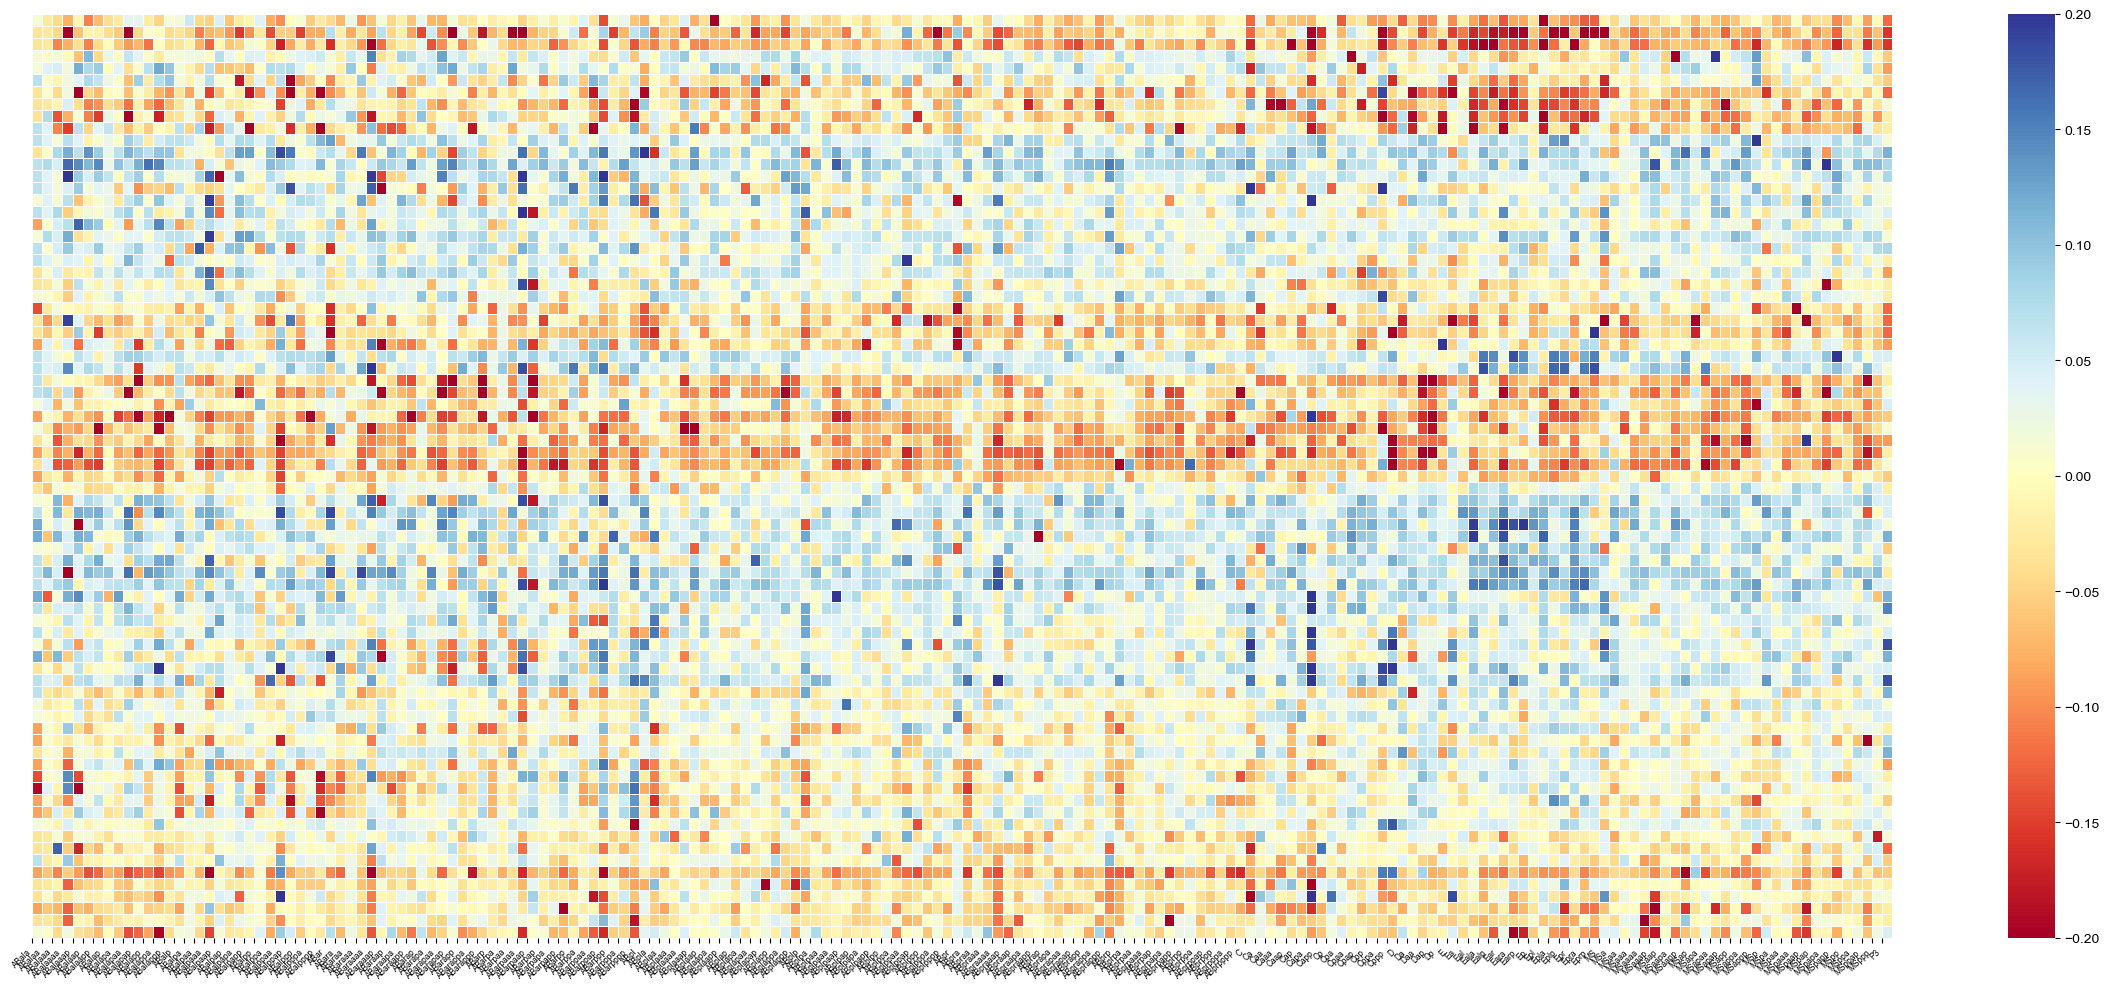

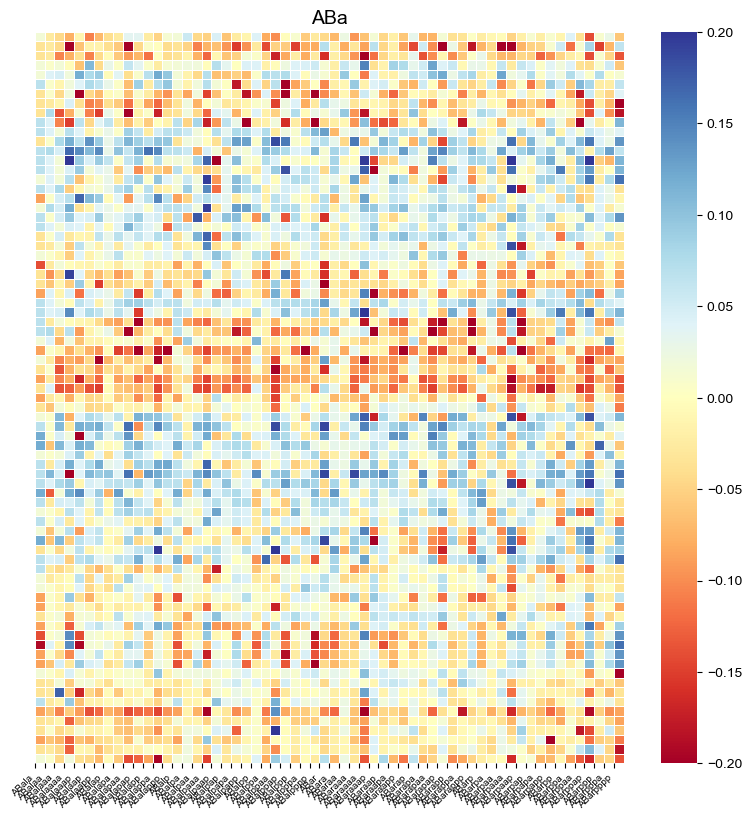

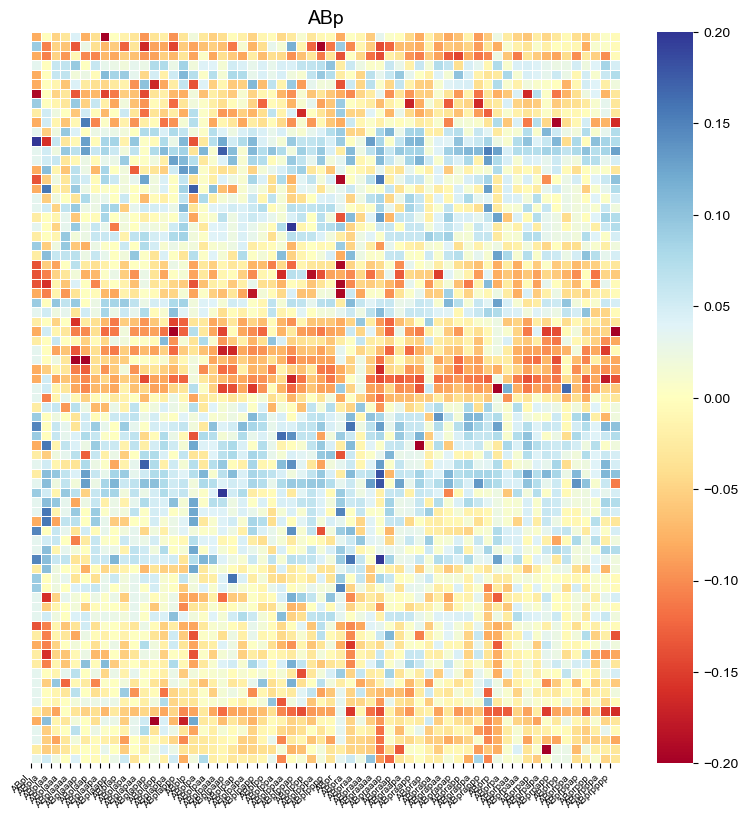

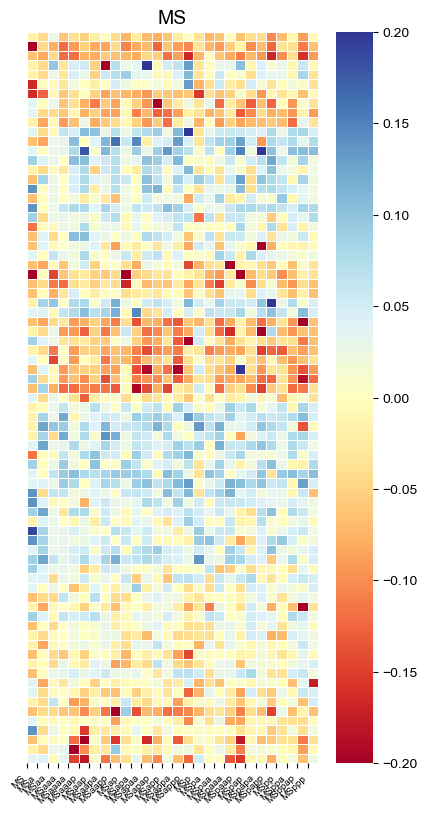

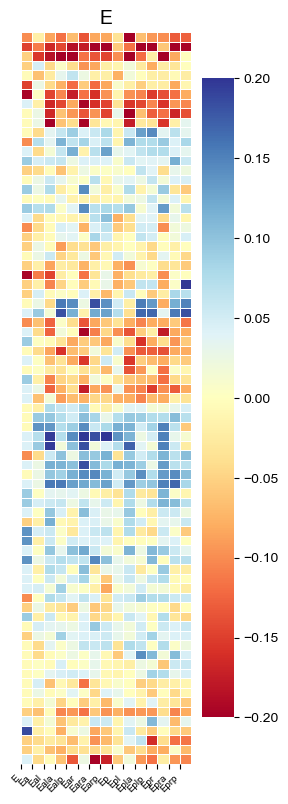

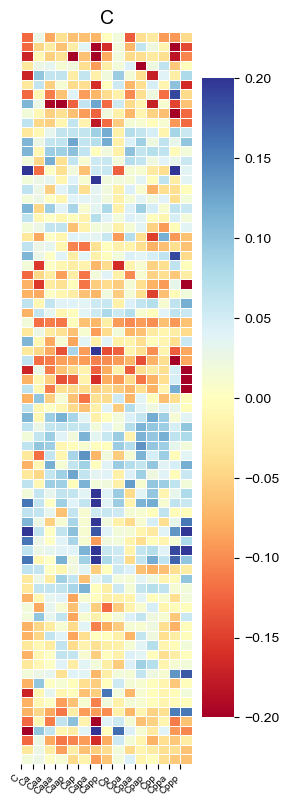

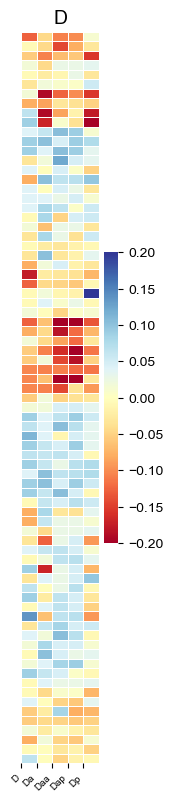

In [7]:
df = pd.DataFrame(fulldictlist)
df = df.sort_index(axis=1)
means = df.mean()
#caption: (mean - observed)/mean, so positive = faster than average
normalized_avg = (means - df)/means
normalized_avg.drop(columns=['ABal'], inplace=True)
print(normalized_avg)
normalized_avg.to_csv('normalized_avg.csv')
#print(df)
plt.figure(figsize=(30, 12)) # Adjust figure size as needed
ax = sns.heatmap(normalized_avg, yticklabels=False, cmap='RdYlBu', fmt=".1f", linewidths=.5, vmin = -0.2, vmax = 0.2)
ax.set_xticks(np.arange(len(normalized_avg.columns)))
ax.set_xticklabels(normalized_avg.columns, rotation=45, ha='right', fontsize=6)
ax.invert_yaxis()
plt.savefig('cell_heatmap.svg', format='svg', bbox_inches='tight')


prefixes = ['ABa', 'ABp', 'MS', 'E', 'C', 'D']
inches_per_cell = 0.15
fixed_height = 9.5
for prefix in prefixes:
    # Filter columns that start with this prefix
    cols = [c for c in normalized_avg.columns if c.startswith(prefix)]
    if len(cols) > 0:
        subset = normalized_avg[cols]
        width = len(cols) * inches_per_cell + 0.5  # Scale width by columns, fixed height
        plt.figure(figsize=(width, fixed_height))
        ax = sns.heatmap(subset, yticklabels=False, cmap='RdYlBu', fmt=".1f", linewidths=.5, vmin=-0.2, vmax=0.2)
        plt.title(f'{prefix}', fontsize=14)
        ax.set_xticks(np.arange(len(subset.columns)))
        ax.set_xticklabels(subset.columns, rotation=45, ha='right', fontsize=7)
        ax.invert_yaxis()
        plt.savefig(f'cell_heatmap_{prefix}.svg', format='svg', bbox_inches='tight')
        plt.show()

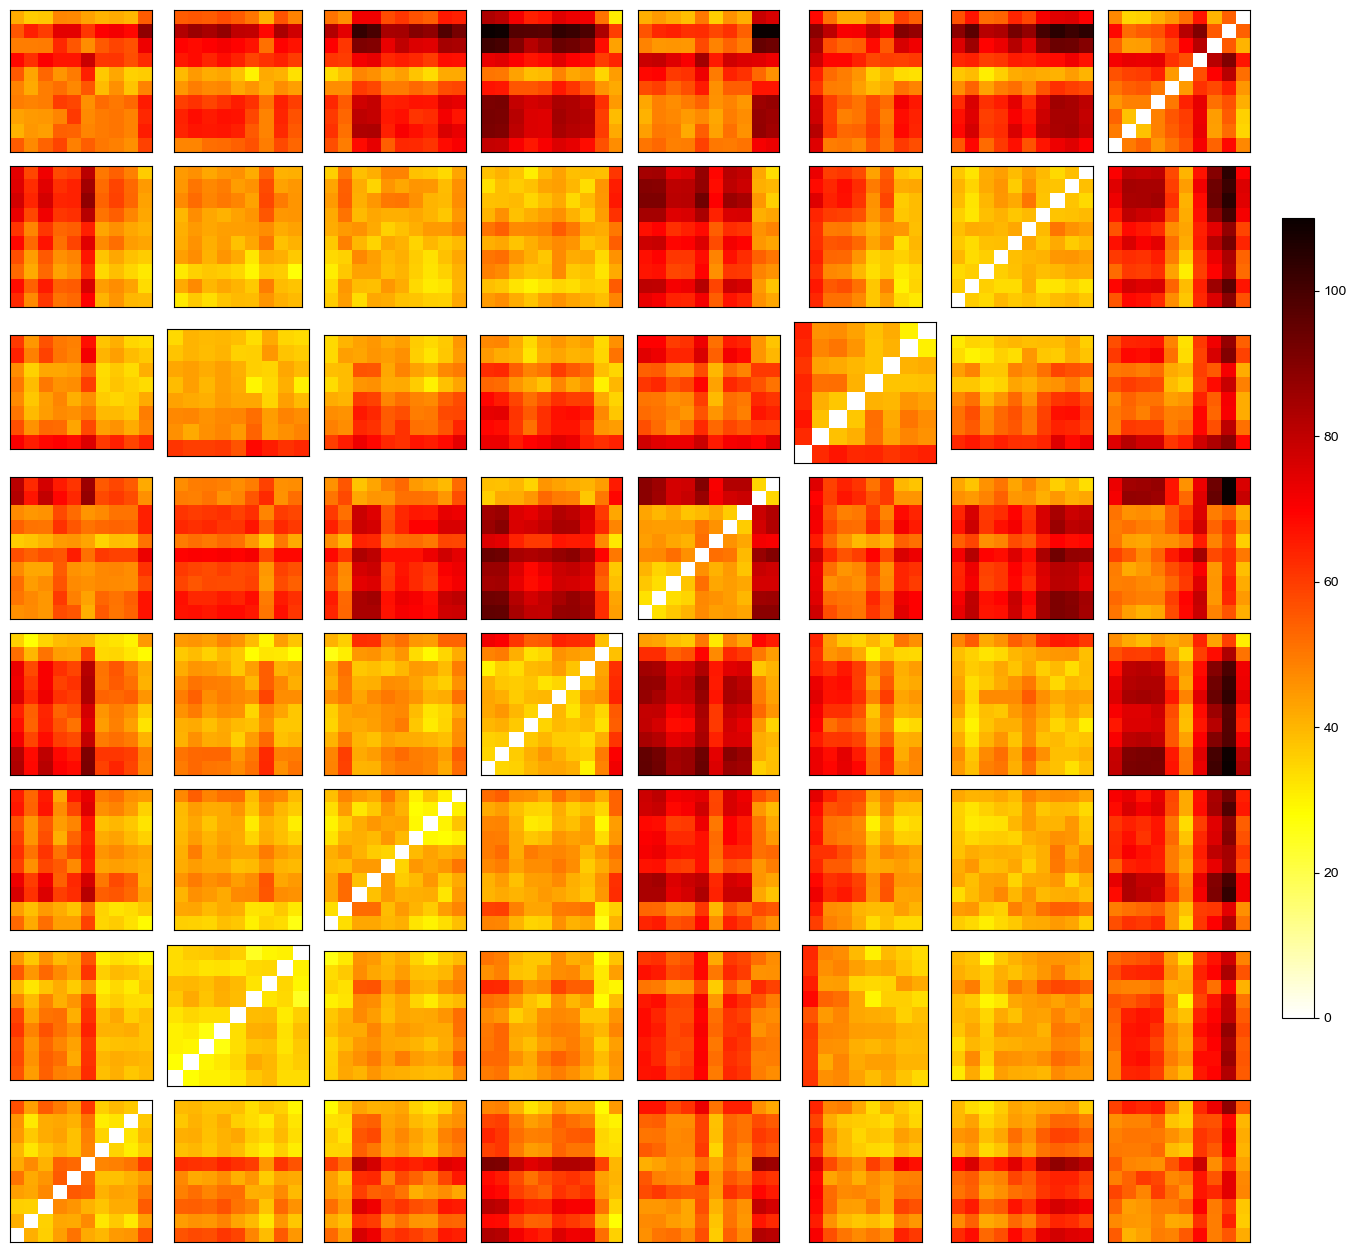

In [8]:
plot_strain_pairwise(dictlists)

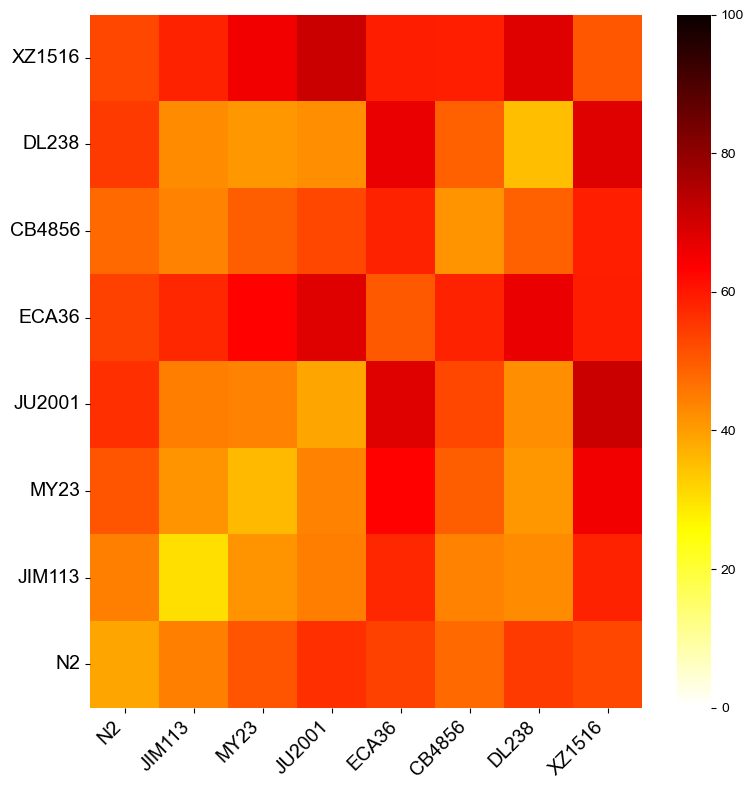

In [9]:
whole_IBD = np.zeros((len(fulldictlist), len(fulldictlist)))
for n in range(len(fulldictlist)):
    for m in range(len(fulldictlist)):
        whole_IBD[n][m] = intersection_branch_distance(fulldictlist[n], fulldictlist[m])
IBD_df = pd.DataFrame(whole_IBD, index=fullnamelist, columns=fullnamelist)
avg_df = average_by_strain(IBD_df)
plot_heatmap(avg_df, "hot_r",0,100, name="whole_embryo_IBD.svg" )
IBD_df.to_csv('IBD_values.csv')

In [10]:
def normalized_decomposition_bd(df):
    """Split each pairwise branch distance into scaling and residual parts.

    For embryos i and j the difference vector is projected onto the bisector
    of their unit cell-cycle vectors. The parallel component measures uniform
    rescaling of developmental tempo, the perpendicular component everything
    else; by construction BD^2 = BD_par^2 + BD_perp^2.

    Returns (parallel_df, perp_df), both square and indexed like `df`.
    """
    M = df.values
    n = M.shape[0]
    #output matrix initialization
    parallel = np.zeros((n,n))
    perp = np.zeros((n,n))
    #iterate through pairwise row comparisons
    for i in range(n):
        for j in range(n):
            #branch distance squared (hypotenuse)
            d2 = np.sum((M[i] - M[j])**2)
            #convert to unit vectors to calculate mean
            u = M[i] / np.linalg.norm(M[i])
            v = M[j] / np.linalg.norm(M[j])
            #mean vector
            m = (u + v) / 2
            norm_m = np.linalg.norm(m)
            if norm_m == 0:
                parallel[i,j] = 0
                perp[i,j] = 0
                continue
            m = m / norm_m
            par = abs(np.dot(M[i] - M[j], m))
            #stil use original vectors for projections
            if d2 == 0: #when comparing identical embs/vectors 
                parallel[i,j] = 0
                perp[i,j] = 0
                continue
            #variance from parallel(scale) and perpendicular(not scale)
            parallel[i,j] = par
            perp[i,j] = math.sqrt(d2 - par**2)
    #output dfs
    parallel_df = pd.DataFrame(parallel, index=df.index, columns=df.index)
    perp_df = pd.DataFrame(perp, index=df.index, columns=df.index)
    return parallel_df, perp_df

normalized_scale, normalized_nonscale = normalized_decomposition_bd(df)
normalized_scale.to_csv('new_scale.csv')
normalized_nonscale.to_csv('new_nonscale.csv')

In [11]:
#Check the decomposition against two embryos whose geometry can be worked out by hand.
samples = [[15, 20, 22], [30, 40, 52]]
df_test = pd.DataFrame(samples, columns=['A', 'B', 'C'])
par, perp = normalized_decomposition_bd(df_test)

bd = math.sqrt((15-30)**2 + (20-40)**2 + (22-52)**2)
assert np.isclose(par.iloc[0, 1]**2 + perp.iloc[0, 1]**2, bd**2), "BD^2 must partition exactly"
assert np.allclose(np.diag(par), 0) and np.allclose(np.diag(perp), 0), "self-comparisons must be 0"
print(f"BD = {bd:.3f} = sqrt(par^2 + perp^2) with par = {par.iloc[0,1]:.3f}, perp = {perp.iloc[0,1]:.3f}")


BD = 39.051 = sqrt(par^2 + perp^2) with par = 38.803, perp = 4.393


In [12]:
def decomp_compute_lineage_means(dictlists):
    """Mean branch distance and its two components for every strain pair.

    `dictlists` maps strain -> list of embryo cell-cycle dicts. For each
    lineage in `lineage_names` the embryos are re-rooted on that founder and
    all strain pairs are scored, excluding self-comparisons.

    Returns (bd_mats, parallel_mats, perp_mats, lineage_names), one square
    strain-by-strain DataFrame per lineage in each list.
    """
    lineage_names = ['whole_embryo', 'ABala','ABalp','ABara','ABarp',
                     'ABpla','ABplp','ABpra','ABprp',
                     'MS','E','C','D']
    strain = list(dictlists.keys())
    lineage_data = {ln: defaultdict(list) for ln in lineage_names}
    for s, embryos in dictlists.items():
        for e in embryos:
            for ln in lineage_names:
                if ln == 'whole_embryo':
                    lineage_data[ln][s].append(e)
                else:
                    lineage_data[ln][s].append(node_comparison_trimmer(e, ln))
    bd_mats = []
    parallel_mats = []
    perp_mats = []
    for ln in lineage_names:
        bd_mat = np.zeros((len(strain), len(strain)))
        par_mat = np.zeros((len(strain), len(strain)))
        perp_mat = np.zeros((len(strain), len(strain)))
        for i, s1 in enumerate(strain):
            for j, s2 in enumerate(strain):
                d_bd = [intersection_branch_distance(e1, e2)
                        for e1 in lineage_data[ln][s1]
                        for e2 in lineage_data[ln][s2]
                        if e1 is not e2]
                bd_mat[i, j] = np.mean(d_bd)
                d = pd.DataFrame(lineage_data[ln][s1] + lineage_data[ln][s2])
                parallel, perpendicular = normalized_decomposition_bd(d)
                #score only the s1 x s2 block, matching bd_mat above
                n1 = len(lineage_data[ln][s1])
                par_block = parallel.values[:n1, n1:]
                perp_block = perpendicular.values[:n1, n1:]
                if s1 == s2:  #drop self-pairs on the within-strain diagonal
                    keep = ~np.eye(n1, dtype=bool)
                    par_block, perp_block = par_block[keep], perp_block[keep]
                par_mat[i, j] = np.mean(par_block)
                perp_mat[i, j] = np.mean(perp_block)
        bd_mats.append(pd.DataFrame(bd_mat, index=strain, columns=strain))
        parallel_mats.append(pd.DataFrame(par_mat, index=strain, columns=strain))
        perp_mats.append(pd.DataFrame(perp_mat, index=strain, columns=strain))
    return bd_mats, parallel_mats, perp_mats, lineage_names

In [13]:
from matplotlib.patches import Circle
from matplotlib.legend_handler import HandlerPatch
from statsmodels.stats.multitest import multipletests

def bh_fdr(matrices):
    """Benjamini-Hochberg adjust p-values pooled across all lineage matrices.

    Within-strain diagonal entries are self-comparisons rather than tests, so
    they are excluded from the pool and returned as NaN.
    """
    #self-comparisons (the diagonal) are not tests; exclude them from the FDR pool
    flat = np.concatenate([m.values.flatten() for m in matrices])
    mask = np.concatenate([
        (~np.eye(m.shape[0], m.shape[1], dtype=bool)).flatten()
        if m.shape[0] == m.shape[1] else np.ones(m.size, dtype=bool)
        for m in matrices])
    qvals = np.full(flat.shape, np.nan)
    _, qvals[mask], _, _ = multipletests(flat[mask], method='fdr_bh')
    out, i = [], 0
    for m in matrices:
        size = m.shape[0]*m.shape[1]
        out.append(pd.DataFrame(qvals[i:i+size].reshape(m.shape),index=m.index, columns=m.columns))
        i += size
    return out


def load_p_values(imports, cwd=None, mode="normal"):
    """Read the per-lineage permutation p-value matrices from `cwd`.

    These CSVs are produced by the permutation testing framework, not by this
    notebook; see README for how they are generated.
    """
    cwd = Path.cwd() if cwd is None else cwd
    matrices, names = [], []

    if mode == "parallel":
        expected_names = [f"{ln}_parallel" for ln in imports]
    elif mode == "perpendicular":
        expected_names = [f"{ln}_perpendicular" for ln in imports]
    else:
        expected_names = imports

    expected_set = set(expected_names)
    for f in sorted(cwd.iterdir(), key=lambda x: x.stem):
        if f.suffix == ".csv" and f.stem in expected_set:
            matrices.append(pd.read_csv(f, index_col=0))
            names.append(f.stem)

    return matrices, names


def make_pvalue_count_table(imports, mode="normal", threshold=0.05, cwd=None):
    """Count significant inter-strain differences per strain and lineage.

    The diagonal is NaN from `bh_fdr`, so counts run 0-7 as in Methods.
    """
    matrices, names = load_p_values(imports, cwd=cwd, mode=mode)
    table = pd.DataFrame()

    qval_mats = bh_fdr(matrices)
    for name, mat in zip(names, qval_mats):
        if mode == "parallel" and name.endswith("_parallel"):
            key = name[:-9]
        elif mode == "perpendicular" and name.endswith("_perpendicular"):
            key = name[:-14]
        else:
            key = name

        bool_version = mat.select_dtypes(include='number') < threshold
        s = bool_version.sum(numeric_only=True)
        table[key] = s

    # Reorder the strain rows to match the global `strain_labels` ordering
    try:
        table = table.reindex(index=strain_labels)
    except Exception:
        # If `strain_labels` is not defined or doesn't match, fall back to existing order
        pass

    table = table.sort_index(axis=1)
    table = table.T

    # Ensure columns follow `strain_labels` order when possible
    try:
        desired_cols = [c for c in strain_labels if c in table.columns]
        other_cols = [c for c in table.columns if c not in desired_cols]
        table = table[desired_cols + other_cols]
    except Exception:
        pass

    table['total'] = table.sum(axis=1)
    return table

def make_cmap():
    """Discrete colormap for q-value bins; untested cells render white."""
    bounds = [0, 0.001, 0.01, 0.05, 1]
    colors = ["#d55e00", "#56b4e9", "#009e73", "#ffffff"]
    cmap = mcolors.ListedColormap(colors)
    cmap.set_bad('white')  #within-strain diagonal: no test performed
    norm = mcolors.BoundaryNorm(bounds, cmap.N)
    return cmap, norm, bounds


def make_figure(n, cols=4, figsize_per=4):
    rows = math.ceil(n/cols)
    fig, axes = plt.subplots(rows, cols, figsize=(figsize_per*cols, figsize_per*rows))
    return fig, axes.flatten()


def plot_circle_panel(ax, mean_mat, q_mat, cmap, norm, title=None):
    """One panel: circle radius ~ log2 mean branch distance, colour = q-value."""
    n = mean_mat.shape[0]
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect('equal')
    ax.set_autoscale_on(False)
    for i in range(n):
        for j in range(n):
            r = math.log(mean_mat.iloc[i,j], 2) * 0.07
            c = cmap(norm(q_mat.iloc[i,j]))
            # place origin at lower-left: use i + 0.5 for y coordinate
            ax.add_patch(Circle(((j + 0.5, i + 0.5)), r, facecolor=c, edgecolor='black', linewidth=0.3))
    x_labels = mean_mat.index.tolist()
    # for origin lower, keep y labels in the same order as x labels
    y_labels = x_labels
    ax.set_xticks(np.arange(n) + 0.5)
    ax.set_yticks(np.arange(n) + 0.5)

    ax.set_xticklabels(x_labels, rotation=90, fontsize=6)
    ax.set_yticklabels(y_labels, fontsize=6)
    ax.set_title(title or "")

In [14]:

def plot_lineage_pvalues(mean_mats, imports, title="title.svg", mode="normal"):
    """Figure 1E / 3B / 4: circle panels for each lineage plus the whole embryo."""
    pval_mats, names = load_p_values(imports, mode=mode)
    pval_dict = {name: mat for name, mat in zip(names, pval_mats)}

    def get_key(ln):
        if mode == "parallel":
            return f"{ln}_parallel"
        elif mode == "perpendicular":
            return f"{ln}_perpendicular"
        else:
            return ln  

    pval_mats = [pval_dict[get_key(ln)] for ln in imports]
    qval_mats = bh_fdr(pval_mats)

    # Reorder rows/columns of mean and q-value matrices to match `strain_labels`
    try:
        desired = list(strain_labels)

        def reorder_df(df):
            existing = [s for s in desired if s in df.index]
            others = [s for s in df.index if s not in existing]
            order = existing + others
            return df.reindex(index=order, columns=order)

        mean_mats = [reorder_df(m) for m in mean_mats]
        qval_mats = [reorder_df(m) for m in qval_mats]
    except Exception:
        pass

    cmap, norm, bounds = make_cmap()

    lineage_idx = [i for i, name in enumerate(imports) if name != "whole_embryo"]
    whole_idx = imports.index("whole_embryo")

    fig = plt.figure(figsize=(16, 8))
    gs = gridspec.GridSpec(3, 5, width_ratios=[1,1,1,1,1.5], wspace=0.25)

    for k, i in enumerate(lineage_idx):
        r, c = divmod(k, 4)
        ax = fig.add_subplot(gs[r, c])
        plot_circle_panel(ax, mean_mats[i], qval_mats[i], cmap, norm, imports[i])

    ax = fig.add_subplot(gs[:, 4])
    plot_circle_panel(ax, mean_mats[whole_idx], qval_mats[whole_idx], cmap, norm, "whole_embryo")

    cax = fig.add_axes([0.88,0.2,0.02,0.55])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cax, boundaries=bounds, ticks=[0,0.001,0.01,0.05])
    cbar.set_label('Adjusted p-value (q)', fontsize=10)

    sizes = [5, 20, 50]
    handles = [
        Circle((0, 0), math.log(s, 2) * 0.07, facecolor='gray', edgecolor='black', label=str(s))
        for s in sizes
    ]

    fig.legend(handles=handles,
               title='Radius size',
               loc='upper left',
               bbox_to_anchor=(0.82, 0.85),
               frameon=False, labelspacing=3,
               handler_map={Circle: HandlerPatch()})
    plt.subplots_adjust(right=0.8, wspace=0.2, hspace=0.4)
    plt.savefig(title)
    plt.show()


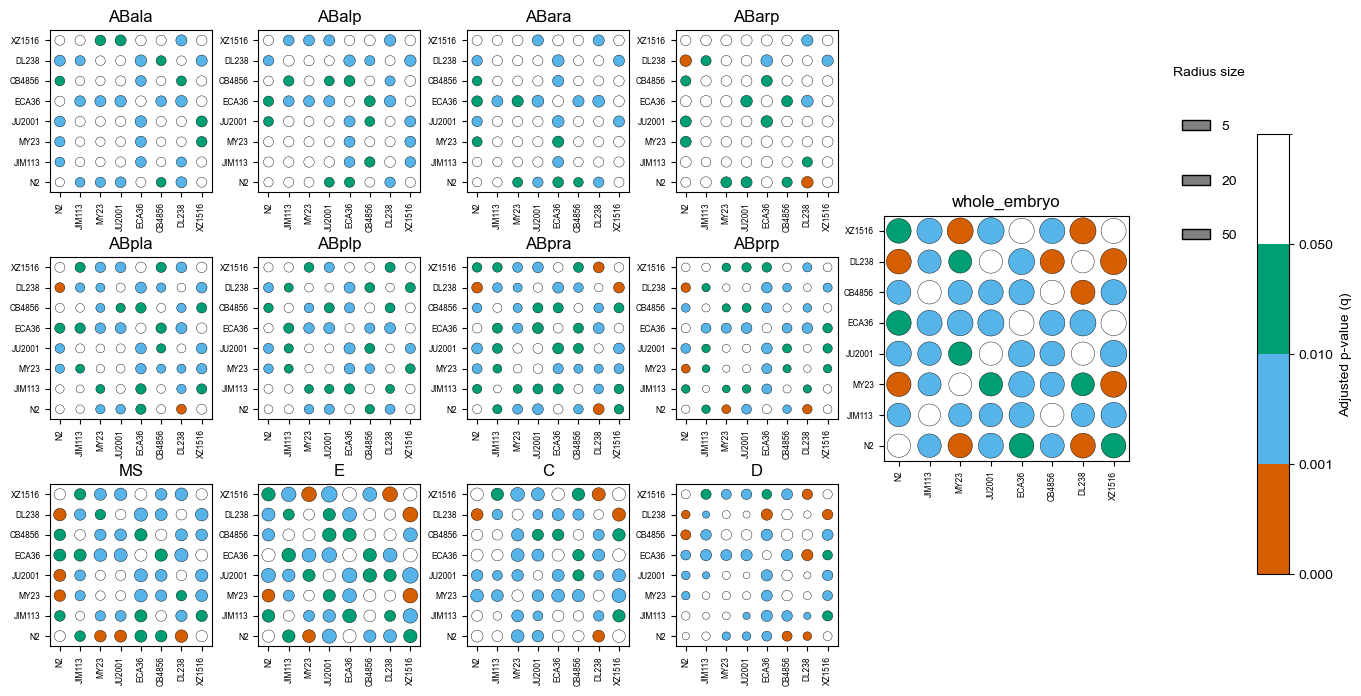

In [15]:
dictlist = {s: strain_lists[s][1] for s in strain_labels}

imports = ['whole_embryo', 'ABala', 'ABalp', 'ABara', 'ABarp',
           'ABpla', 'ABplp', 'ABpra', 'ABprp',
           'MS', 'E', 'C', 'D']
whole_means, parallel, perp, lineages = decomp_compute_lineage_means(dictlist)
assert lineages == imports, "panel labels must match the order the matrices come back in"
plot_lineage_pvalues(whole_means, imports, "Whole_BD.svg", mode="normal")


## Figure 2: Intra-strain developmental variation

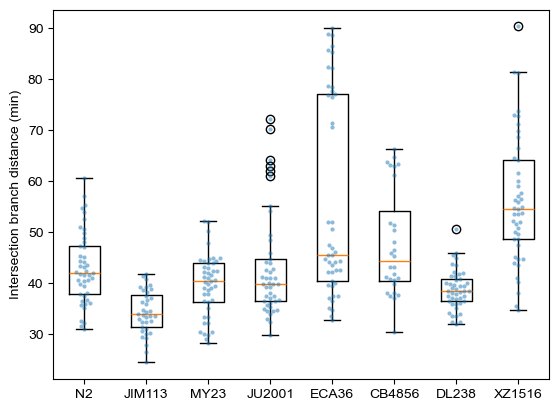

N2        43.03
JIM113    34.28
MY23      39.63
JU2001    43.16
ECA36     55.97
CB4856    47.70
DL238     38.76
XZ1516    56.22
dtype: float64


In [16]:
#Figure 2A: within-strain branch distances, one distribution per strain.
all_values = []
mean_dict = {}

for label, embryos in zip(strain_labels, dictlists):
    motmat = intersection_generator(embryos, embryos)
    upper_vals = motmat[np.triu_indices(len(embryos), k=1)]
    mean_dict[label] = sum(upper_vals) / len(upper_vals)
    all_values.append(upper_vals)

plt.figure()
bp = plt.boxplot(all_values, positions=range(0, len(strain_labels)), widths=0.5)

# swarmplot
sns.swarmplot(
    x=np.concatenate([[strain_labels[i]] * len(vals) for i, vals in enumerate(all_values)]),
    y=np.concatenate(all_values),
    size=3,
    alpha=0.5
)
plt.xticks(range(len(strain_labels)), strain_labels)
plt.ylabel('Intersection branch distance (min)')
plt.savefig('IBD_intrastrain_boxplot.svg', format='svg', bbox_inches='tight')
plt.show()

print(pd.Series(mean_dict).round(2))


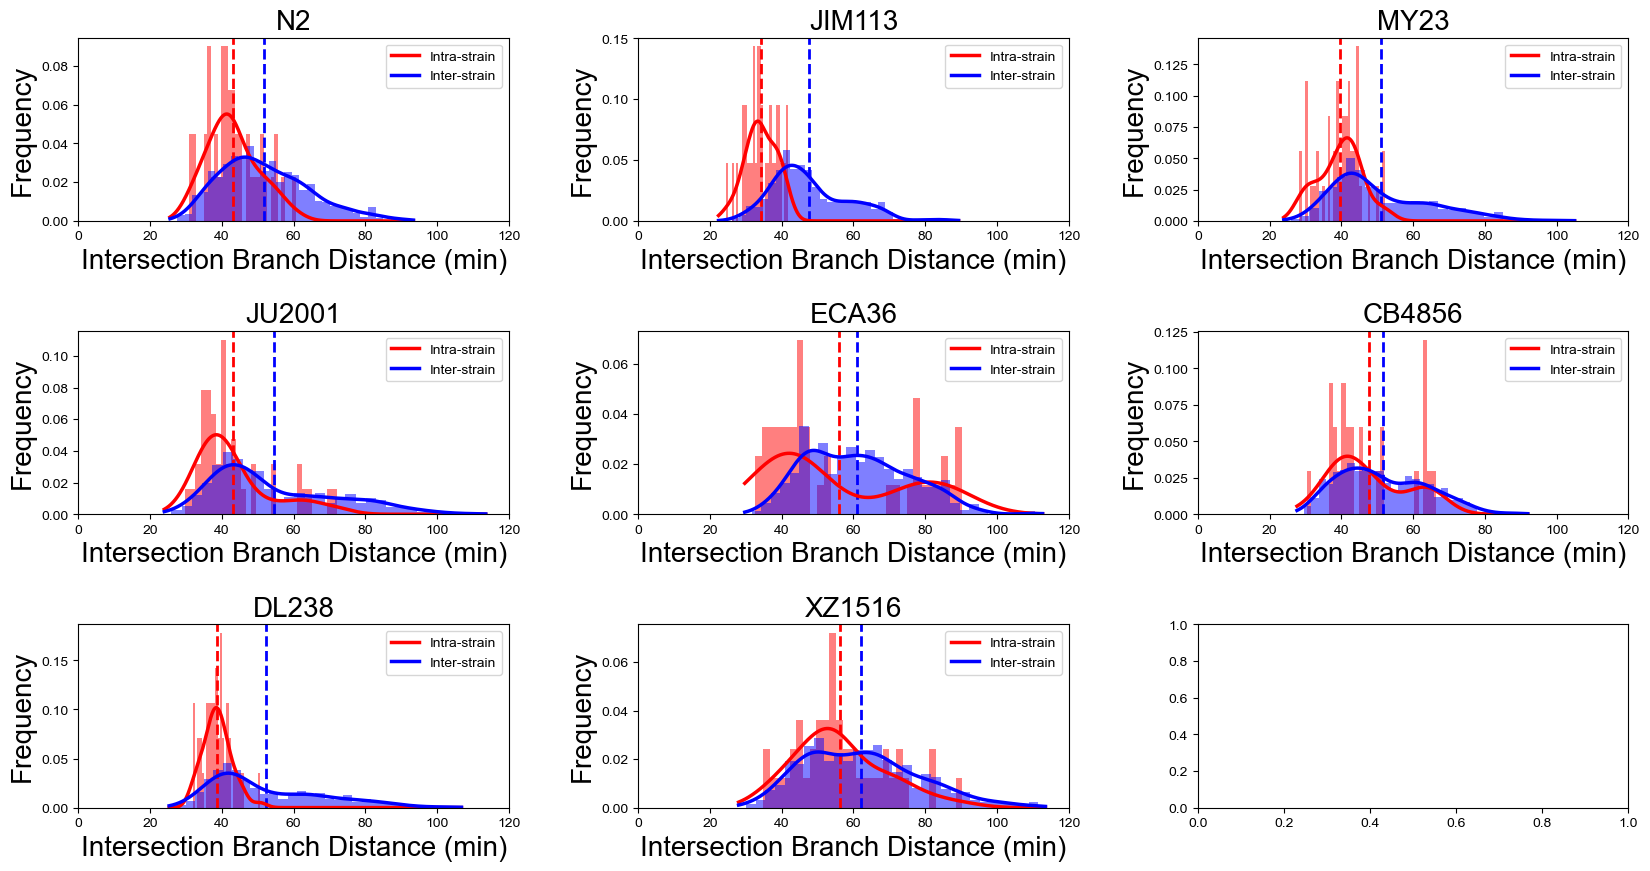

In [17]:
from scipy.stats import gaussian_kde
def pairwise_KDE(dictlists):
    """Figure S1: within- vs between-strain branch distance distributions."""
    n = len(dictlists)
    fig, axes = plt.subplots(3, 3, figsize=(20, 10))
    axes = axes.flatten()
    for i in range(n):
        #calculate distributions for inter and intra BD values
        intra_mat = intersection_generator(dictlists[i], dictlists[i])
        intra_vals = intra_mat[np.triu_indices(len(intra_mat), k=1)]
        inter_vals = []
        for j in range(n):
            if i != j:
                mat = intersection_generator(dictlists[i], dictlists[j])
                inter_vals.extend(mat.flatten())
        inter_vals = np.asarray(inter_vals)
        #flatten and calculate KDE pdfs
        kde_intra = gaussian_kde(intra_vals)
        kde_inter = gaussian_kde(inter_vals)
        all_vals = np.concatenate([intra_vals, inter_vals])
        x_grid = np.linspace(all_vals.min() - 2, all_vals.max() + 2, 1000)
        kde_pdf_intra = kde_intra(x_grid)
        kde_pdf_inter = kde_inter(x_grid)
        ax = axes[i]
        #put on same plot, colors, size
        ax.axvline(intra_vals.mean(), color='red', linestyle='--', lw=2)
        ax.axvline(inter_vals.mean(), color='blue', linestyle='--', lw=2)
        ax.hist(intra_vals, bins=30, density=True, alpha=0.5, color='red')
        ax.hist(inter_vals, bins=30, density=True, alpha=0.5, color='blue')
        ax.plot(x_grid, kde_pdf_intra, color='red', lw=2.5, label='Intra-strain')
        ax.plot(x_grid, kde_pdf_inter, color='blue', lw=2.5, label='Inter-strain')
        ax.set_xlim(0, 120)
        ax.set_xlabel('Intersection Branch Distance (min)', fontsize=20)
        ax.set_ylabel('Frequency', fontsize=20)
        ax.set_title(strain_labels[i], fontsize=20)
        ax.legend()
    plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=0.6)
    plt.savefig("KDE_supplement.svg", format="svg")
    plt.show()

pairwise_KDE(dictlists)

### Figure 2E-F: Hierarchical clustering of all embryos

In [18]:
def clustering_function(embryo_list, met):
    """Cluster all embryos on the branch distance matrix and plot the heatmap.

    Returns the row linkage so that it can be cut with `fcluster`.
    """
    motmat = np.zeros((len(embryo_list),len(embryo_list)))
    for n in range(len(embryo_list)):
        for m in range(len(embryo_list)):
            motmat[n,m] = intersection_branch_distance(embryo_list[n],embryo_list[m])
    df = pd.DataFrame(motmat, index=fullnamelist, columns=fullnamelist)
    #df is a distance matrix, so condense it and cluster on the branch distance
    #itself rather than on Euclidean distance between rows of the matrix
    link = linkage(squareform(motmat, checks=False), method=met)
    cg = sns.clustermap(
        df,
        row_linkage=link,
        col_linkage=link,
        cmap='hot_r',
        linewidths=0,
        dendrogram_ratio=(0.2, 0.2),
        cbar_pos=(0.76, 0.30, 0.02, 0.55),
        figsize=(12, 12)
    )
    #make dendrogram lines thicker
    for ax in [cg.ax_row_dendrogram, cg.ax_col_dendrogram]:
        for line in ax.collections:
            line.set_linewidth(1.75)   
    cg.ax_heatmap.set_xticklabels([])
    cg.ax_heatmap.set_yticklabels([])
    cg.ax_heatmap.tick_params(bottom=False, left=False)
    cg.ax_heatmap.invert_xaxis()
    cg.ax_col_dendrogram.invert_xaxis()
    plt.figtext(0.5, 0.95, f"Clustering with {met} linkage", fontsize=16, ha='center')
    plt.savefig(f"clustering_heatmap_{met}.svg", format="svg", bbox_inches='tight')
    plt.show()
    return cg.dendrogram_row.linkage

In [19]:
print(len(fulldictlist))

77


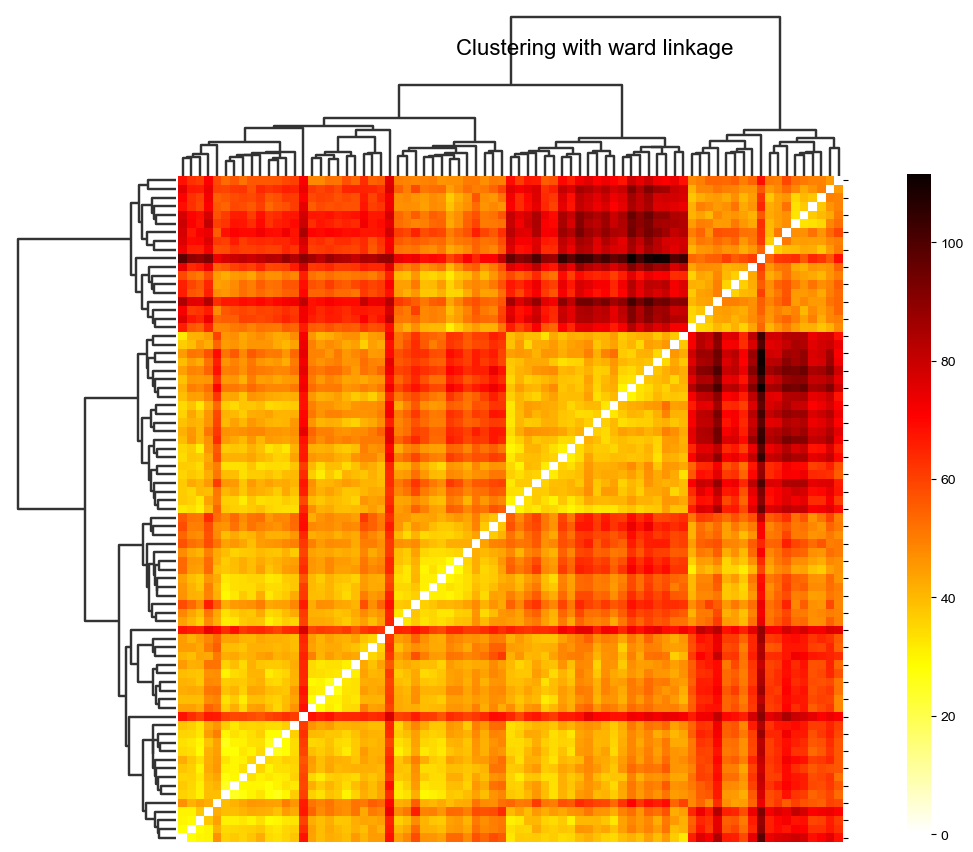

In [20]:
data = clustering_function(fulldictlist, 'ward')

In [23]:
k = 3
clusters = fcluster(data, k, criterion='maxclust')
dictmap = {}
for n in range(len(clusters)):
    dictmap[fullnamelist[n]] = clusters[n]
simplified = {}
for key,value in dictmap.items():
    strain = key.split('_')[1]
    if strain not in simplified:
        simplified[strain] = []
    simplified[strain].append(int(value))

In [24]:

strains = list(simplified.keys())
clusters = [1, 2, 3]

labels = strains + [f"Cluster {c}" for c in clusters]

strain_idx = {s: i for i, s in enumerate(strains)}
cluster_idx = {c: i + len(strains) for i, c in enumerate(clusters)}

sources, targets, values, link_colors = [], [], [], []

for strain, assignments in simplified.items():
    counts = Counter(assignments)
    for cluster, count in counts.items():
        sources.append(strain_idx[strain])
        targets.append(cluster_idx[cluster])
        values.append(count)
        link_colors.append(strain_colors[strain])

# node colors: strain colors first, neutral cluster colors second
node_colors = (
    [strain_colors[s] for s in strains] +
    ['#d9d9d9'] * len(clusters)
)

fig = go.Figure(go.Sankey(
    node=dict(
        pad=24,            # close together
        thickness=20,     # skinnier bars
        line=dict(color="black", width=0.5),
        label=[""]*(len(strains) + len(clusters)),  # hide labels
        color=node_colors
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color=link_colors
    )
))

fig.update_layout(
    title_text="Cluster Assignments on a Strain-by-Strain Basis",
    font=dict(
        family="Arial",
        size=14
    ),
    height=900
)

fig.write_image("sankey_diagram.svg")

fig.show()


## Figure 3: Inter-strain differences in developmental timing

In [25]:
#import the cell cycle csv
df = pd.read_csv("cell_cycles.csv", index_col=0)
df.drop(EXCLUDED_EMBRYOS, inplace=True)  #same cohort as cell 2
#df.drop(['ABa', 'ABp','EMS', 'P2'], axis=1, inplace=True)
#add P4 with a value of nan if not present in df
added = ['P4', 'Z2', 'Z3']
for cell in added:
    if cell not in df. columns:
        df[cell] = np.nan

In [26]:
#Per-cell fold-change relative to the dataset-wide mean, averaged within strain.
df["strain"] = df.index.map(get_strain)
global_avg = df.drop(columns="strain").mean(numeric_only=True)
strain_avg = df.groupby("strain").mean(numeric_only=True)

difference = strain_avg - global_avg
rate = strain_avg / global_avg


{'RLJ_N2_020923_s1_emb1_1_edited.csv': 18.41687754523874, 'RLJ_N2_020923_s2_emb1_NNNLT1_edited.csv': 20.547206098717474, 'RLJ_N2_020923_s3_emb1_1_edited.csv': 19.71611601276374, 'RLJ_N2_020923_s4_emb1_1_edited.csv': 20.62366819873873, 'RLJ_N2_020923_s6_emb1_retry1_edited.csv': 19.153670287815018, 'RLJ_N2_020923_s7_emb1_1_edited.csv': 18.350138695027493, 'RLJ_N2_020923_s7_emb2_1_edited.csv': 21.030617802295065, 'RLJ_N2_021023_s1_emb1_new1_edited.csv': 21.627017559899997, 'RLJ_N2_021023_s2_emb1_1_edited.csv': 23.462489149335006, 'RLJ_N2_021023_s3_emb1_1_edited.csv': 21.833303811108745, 'RLJ_CB4856_022723_s2_emb1_1_edited.csv': 23.99678113995, 'RLJ_CB4856_022723_s3_emb1_1_edited.csv': 24.133627964025003, 'RLJ_CB4856_022723_s4_emb1_1_edited.csv': 23.305379201673748, 'RLJ_CB4856_022723_s6_emb1_1_edited.csv': 23.120914550309994, 'RLJ_CB4856_041323_1_s1_emb2_1_edited.csv': 20.68775192147623, 'RLJ_CB4856_041723_s1_emb1_1_edited.csv': 22.3213707801225, 'RLJ_CB4856_041723_s3_emb2_1_edited.csv': 

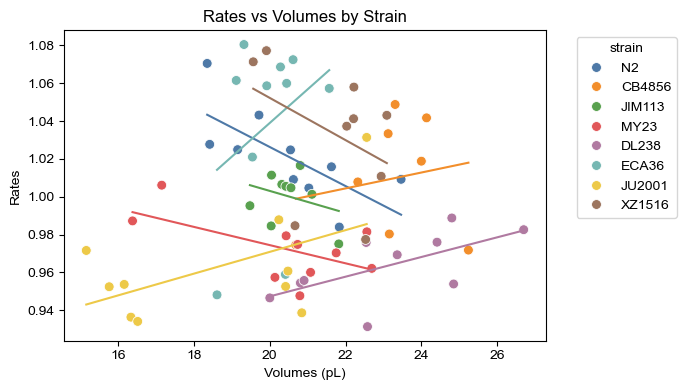

In [27]:

with open('volumes.pickle', 'rb') as file:
    volume_dict = pickle.load(file)

    
for k in EXCLUDED_EMBRYOS:
    volume_dict.pop(k, None)

pl_dict = {}
for key, value in volume_dict.items():
    pl_dict[key] = value / 1000
print(pl_dict)
cell_means = df.mean(numeric_only=True)
cell_rate = df / cell_means
rates = cell_rate.mean(axis=1)

plotting = rates.to_frame('rates')
plotting['volumes'] = plotting.index.map(pl_dict)
plotting["strain"] = plotting.index.map(get_strain)

plt.figure(figsize=(7, 4))
ax = sns.scatterplot(
    data=plotting,
    x='volumes',
    y='rates',
    hue='strain',        
    palette=strain_colors,     
    s=50                 
)
plotting.dropna(subset=['volumes', 'rates'], inplace=True)  #drop nans
for strain in plotting['strain'].unique():
    color = strain_colors[strain]
    subset = plotting[plotting['strain'] == strain]
    # Fit a line
    m, b = np.polyfit(subset['volumes'].values.astype(float), subset['rates'].values.astype(float), 1)
    # Plot the line
    x_vals = np.array([subset['volumes'].min(), subset['volumes'].max()])
    y_vals = m * x_vals + b
    ax.plot(x_vals, y_vals, color=color)

#move legend to the right
plt.legend(title='strain', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xlabel('Volumes (pL)')
plt.ylabel('Rates')
plt.title('Rates vs Volumes by Strain')
plt.tight_layout()

plt.savefig("Rate_vs_volume.svg", format="svg")
plt.show()

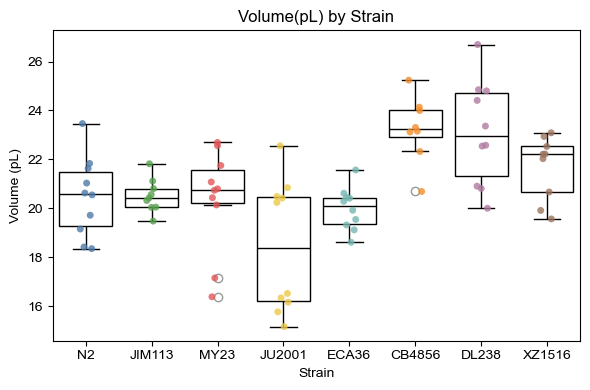

In [28]:
# ensure the x-axis follows the desired strain ordering
plotting['strain'] = pd.Categorical(plotting['strain'], categories=strain_labels, ordered=True)
plotting = plotting.sort_values('strain')

plt.figure(figsize=(6, 4))

ax = sns.boxplot(
    data=plotting,
    x='strain',
    y='volumes',
    order=strain_labels,
    color='white',
    boxprops=dict(facecolor='none', edgecolor='black'),
    whiskerprops=dict(color='black'),
    capprops=dict(color='black'),
    medianprops=dict(color='black')
)

sns.stripplot(
    data=plotting,
    x='strain',
    y='volumes',
    hue='strain',
    palette=strain_colors,
    order=strain_labels,
    size=5,
    alpha=0.8,
    ax=ax,
    jitter=True
)

if ax.get_legend() is not None:
    ax.get_legend().remove()

plt.ylabel("Volume (pL)")
plt.xlabel("Strain")
plt.title("Volume(pL) by Strain")
plt.tight_layout()

plt.savefig("Volume_by_strain.svg", format="svg")
plt.show()

{'RLJ_N2_020923_s1_emb1_1_edited.csv': 18.41687754523874, 'RLJ_N2_020923_s2_emb1_NNNLT1_edited.csv': 20.547206098717474, 'RLJ_N2_020923_s3_emb1_1_edited.csv': 19.71611601276374, 'RLJ_N2_020923_s4_emb1_1_edited.csv': 20.62366819873873, 'RLJ_N2_020923_s6_emb1_retry1_edited.csv': 19.153670287815018, 'RLJ_N2_020923_s7_emb1_1_edited.csv': 18.350138695027493, 'RLJ_N2_020923_s7_emb2_1_edited.csv': 21.030617802295065, 'RLJ_N2_021023_s1_emb1_new1_edited.csv': 21.627017559899997, 'RLJ_N2_021023_s2_emb1_1_edited.csv': 23.462489149335006, 'RLJ_N2_021023_s3_emb1_1_edited.csv': 21.833303811108745, 'RLJ_CB4856_022723_s2_emb1_1_edited.csv': 23.99678113995, 'RLJ_CB4856_022723_s3_emb1_1_edited.csv': 24.133627964025003, 'RLJ_CB4856_022723_s4_emb1_1_edited.csv': 23.305379201673748, 'RLJ_CB4856_022723_s6_emb1_1_edited.csv': 23.120914550309994, 'RLJ_CB4856_041323_1_s1_emb2_1_edited.csv': 20.68775192147623, 'RLJ_CB4856_041723_s1_emb1_1_edited.csv': 22.3213707801225, 'RLJ_CB4856_041723_s3_emb2_1_edited.csv': 

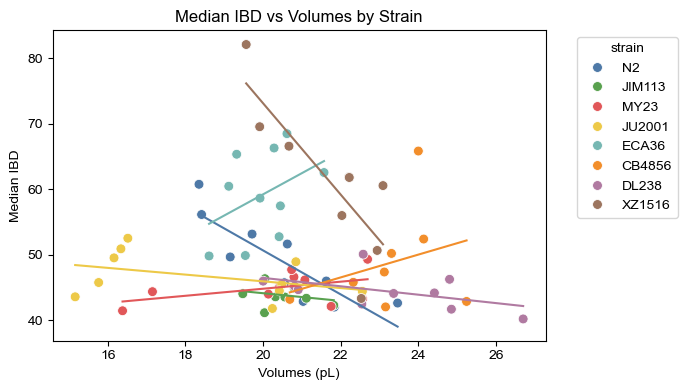

In [29]:
#median IBD vs. volume
print(pl_dict)
IBD = intersection_generator(fulldictlist, fulldictlist)
IBD_df = pd.DataFrame(IBD, index=fullnamelist, columns=fullnamelist)
median_IBD = IBD_df.median(axis=1)
median_IBD_df = median_IBD.to_frame('median_IBD')
median_IBD_df['volumes'] = median_IBD_df.index.map(pl_dict)
median_IBD_df['strain'] = median_IBD_df.index.map(get_strain)
#plot median IBD vs volume
plt.figure(figsize=(7, 4))
ax = sns.scatterplot(
    data=median_IBD_df,
    x='volumes',
    y='median_IBD',
    hue='strain',        
    palette=strain_colors,     
    s=50                 
)
median_IBD_df.dropna(subset=['volumes', 'median_IBD'], inplace=True)  #drop nans
for strain in median_IBD_df['strain'].unique():
    color = strain_colors[strain]
    subset = median_IBD_df[median_IBD_df['strain'] == strain]
    # Fit a line
    m, b = np.polyfit(subset['volumes'].values.astype(float), subset['median_IBD'].values.astype(float), 1)
    # Plot the line
    x_vals = np.array([subset['volumes'].min(), subset['volumes'].max()])
    y_vals = m * x_vals + b
    ax.plot(x_vals, y_vals, color=color)
#move legend to the right
plt.legend(title='strain', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.xlabel('Volumes (pL)')
plt.ylabel('Median IBD')
plt.title('Median IBD vs Volumes by Strain')
plt.tight_layout()

plt.savefig("Median_IBD_vs_volume.svg", format="svg")
plt.show()

Figure 3: Interstrain Variation

In [30]:
# script that defines necessary functions to draw a lineage map

def draw_lineage(
    cell_names: Iterable[str],
    edge_lengths: Iterable[float],
    values: Iterable[float],
    *,
    DefaultLength: float = 10.0,
    CMap: Optional[Union[str, np.ndarray, ListedColormap]] = "viridis",  # parula≈viridis
    CLim: Optional[Tuple[float, float]] = None,
    LineWidth: float = 2.0,
    NaNColor: Tuple[float, float, float] = (0.8, 0.8, 0.8),
    ShowLabels: bool = True,
    LabelRotation: Optional[float] = None,
    LabelFontSize: float = 8.0,
    Root: str = "P0",
    Orientation: str = "vertical",          # 'vertical' or 'horizontal'
    TimeDown: bool = True, 
    Title: Optional[str] = None # only used if vertical
) -> Dict[str, Any]:
    """
    Sulston-style lineage plot with value-based coloring.

    Returns:
        {
          'nodes': pandas.DataFrame(columns=['name','t0','t1','pos','length','value','parent','children']),
          'ax': matplotlib.axes.Axes
        }
    """
    # ---- normalize & validate inputs ----
    names = [str(n) for n in cell_names]
    lengths = np.asarray(list(edge_lengths), dtype=float).reshape(-1)
    vals = np.asarray(list(values), dtype=float).reshape(-1)
    assert len(names) == len(lengths) == len(vals), "Inputs must match size."

    orientation = Orientation.lower()
    assert orientation in ("vertical", "horizontal"), "Orientation must be 'vertical' or 'horizontal'."
    is_vertical = orientation == "vertical"

    # ---- build node map (add missing ancestors) ----
    M: Dict[str, Node] = {}
    for n, L, v in zip(names, lengths, vals):
        # If length is zero or negative, replace with DefaultLength
        L_use = float(L) if float(L) > 0 else float(DefaultLength)
        M[n] = Node(name=n, length=L_use, value=float(v))

    # ensure ancestry to Root
    for n in list(M.keys()):
        cur = n
        while True:
            par = parent_of(cur)
            if not par:
                break
            if par not in M:
                M[par] = Node(name=par, length=float(DefaultLength), value=np.nan)  # synthesize ancestor
            cur = par

    # ensure root exists
    root_key = str(Root)
    if root_key not in M:
        M[root_key] = Node(name=root_key, length=float(DefaultLength), value=np.nan)

    # ---- wire parents/children ----
    for nm in list(M.keys()):
        par = parent_of(nm)
        nd = M[nm]
        nd.parent = par
        if par:
            ch = list(M[par].children)
            if nm not in ch:
                ch.append(nm)
            M[par].children = order_children(ch, par)

    # ---- compute horizontal positions (left/right aware) ----
    pos_counter = 1
    root_list, _ = roots_of_forest(M, root_key)
    for r in root_list:
        pos_counter = assign_pos(M, r, pos_counter)

    # ---- compute times from edge lengths ----
    for r in root_list:
        assign_time(M, r, t0=0.0)

    # ---- gather table for plotting ----
    rows = []
    for k in M.keys():
        nd = M[k]
        rows.append(dict(
            name=nd.name,
            t0=nd.t0,
            t1=nd.t1,
            pos=nd.pos,               # stored 'y' as "pos"
            length=nd.length,
            value=nd.value,
            parent=nd.parent or "",
            children=",".join(nd.children),
        ))
    T = pd.DataFrame(rows, columns=['name','t0','t1','pos','length','value','parent','children'])

       # ---- plotting ----
    fig, ax = plt.subplots(figsize=(12, 6))   # wider figure
    ax.cla()
    #ax.box(True)

    # colormap + clim
    # colormap + clim (discretized)
    base_cmap = _resolve_cmap(CMap)

    # Number of discrete bins
    N_bins = 9  # you can change this value if you want more/fewer color levels
    colors = base_cmap(np.linspace(0, 1, N_bins))
    cmap = ListedColormap(colors)

    if CLim is None:
        vfinite = T["value"].to_numpy()[np.isfinite(T["value"].to_numpy())]
        clim = (0.0, 1.0) if vfinite.size == 0 else (float(np.min(vfinite)), float(np.max(vfinite)))
    else:
        assert len(CLim) == 2, "CLim must be a (vmin, vmax) pair."
        clim = (float(CLim[0]), float(CLim[1]))
    #ax.set_clim(*clim)
    #ax.set_colormap(cmap)

    lw = float(LineWidth)
    label_rot = (90.0 if is_vertical else 0.0) if (LabelRotation is None) else float(LabelRotation)


    if is_vertical:
        # time on y, splits are horizontal connectors
        ax.set_ylim(None)  # let autoscale happen
        ax.set_xlim(None)
        ax.set_ybound(lower=None, upper=None)
        ax.set_xbound(lower=None, upper=None)
        ax.set_ylim(ax.get_ylim())  # ensure exists
        ax.set_ybound  # silence linter

        ax.set_ylim(min(T['t0'].min(), T['t1'].min()), max(T['t0'].max(), T['t1'].max()))
        ax.invert_yaxis() if TimeDown else None

        # colored vertical edges
        for _, row in T.iterrows():
            c = val2rgb(row['value'], cmap, clim, NaNColor)
            lw_use = lw if np.isfinite(row['value']) else 0.5 * lw   # thinner if NaN
            x = row['pos']
            ax.plot([x, x], [row['t0'], row['t1']], linewidth=lw_use, color=c)
            if ShowLabels and np.isfinite(row['value']):
                ax.text(
                    x, 0.5*(row['t0']+row['t1']), row['name'],
                    ha='center', va='bottom', rotation=label_rot,
                    fontsize=LabelFontSize, color=(0.2,0.2,0.2)
                )


        # grey horizontal connectors at division time
        for _, row in T.iterrows():
            ch = [s for s in row['children'].split(',') if s]
            if ch:
                y = row['t1']; x0 = row['pos']
                for cj in ch:
                    idx = np.where(T['name'].to_numpy() == cj)[0]
                    if idx.size:
                        x1 = T.iloc[idx[0]]['pos']
                        ax.plot([x0, x1], [y, y], color=(0.5,0.5,0.5), linewidth=0.75)

        ax.set_xticks([])
        ax.set_ylabel('Time (min)')

    else:
        # time on x, splits are vertical connectors
        for _, row in T.iterrows():
            c = val2rgb(row['value'], cmap, clim, NaNColor)
            lw_use = lw if np.isfinite(row['value']) else 0.5 * lw   # thinner if NaN
            x = row['pos']
            ax.plot([x, x], [row['t0'], row['t1']], linewidth=lw_use, color=c)
            if ShowLabels and np.isfinite(row['value']):
                ax.text(
                    x, 0.5*(row['t0']+row['t1']), row['name'],
                    ha='center', va='bottom', rotation=label_rot,
                    fontsize=LabelFontSize, color=(0.2,0.2,0.2)
                )

        ax.set_xlabel('Time (min)')
        ax.set_ylabel('Lineage')

    plt.colorbar(mappable=_dummy_scalar_mappable(cmap, clim), ax=ax)
    ax.autoscale(enable=True, tight=True)
    if Title:
        ax.set_title(Title, fontsize=12, pad=10)
    return {"nodes": T.sort_values("t0").reset_index(drop=True), "ax": ax}


# ---------------------------- internals ----------------------------

@dataclass
class Node:
    name: str
    length: float
    value: float
    parent: Optional[str] = None
    children: List[str] = field(default_factory=list)
    t0: float = np.nan
    t1: float = np.nan
    pos: float = np.nan   # horizontal position (called 'y' in MATLAB)

def parent_of(nm: str) -> str:
    nm = str(nm)
    if nm == "P0":
        return ""
    fixed = {
        "AB": "P0", "P1": "P0",
        "EMS": "P1", "P2": "P1",
        "MS": "EMS", "E": "EMS",
        "C": "P2", "P3": "P2",
        "D": "P3", "P4": "P3",
        "Z2": "P4", "Z3": "P4",
    }
    if nm in fixed:
        return fixed[nm]
    if nm and nm[-1] in "aplr dv".replace(" ", ""):  # a,p,l,r,d,v
        return nm[:-1]
    return ""

def is_right_child(child: str, parent: str) -> bool:
    child = str(child); parent = str(parent)
    special = {
        "P0": "P1", "P1": "P2", "EMS": "E", "P2": "P3", "P3": "P4", "P4": "Z3"
    }
    if parent in special:
        return child == special[parent]
    return child.endswith(("p","r","v"))

def order_children(lst: List[str], parent: str) -> List[str]:
    if len(lst) <= 1:
        return list(lst)
    left, right = [], []
    for ch in lst:
        (right if is_right_child(ch, parent) else left).append(ch)
    return left + right

def assign_pos(M: Dict[str, Node], root: str, pos_counter: int) -> int:
    nd = M[root]
    if not nd.children:
        nd.pos = float(pos_counter)
        M[root] = nd
        return pos_counter + 1
    ys = []
    for ch in nd.children:
        pos_counter = assign_pos(M, ch, pos_counter)
        ys.append(M[ch].pos)
    nd.pos = float(np.mean(ys))
    M[root] = nd
    return pos_counter

def assign_time(M: Dict[str, Node], root: str, t0: float) -> None:
    nd = M[root]
    nd.t0 = float(t0)
    nd.t1 = float(t0 + nd.length)
    M[root] = nd
    for ch in nd.children:
        assign_time(M, ch, nd.t1)

def roots_of_forest(M: Dict[str, Node], preferred_root: str) -> Tuple[List[str], List[Optional[str]]]:
    K = list(M.keys())
    parents = [M[k].parent for k in K]
    is_root = [p in (None, "") for p in parents]
    roots = [k for k, r in zip(K, is_root) if r]
    if preferred_root in roots:
        i = roots.index(preferred_root)
        roots = [roots[i]] + roots[:i] + roots[i+1:]
    return roots, parents

def _resolve_cmap(cmap_like) -> ListedColormap:
    if isinstance(cmap_like, (np.ndarray, list)):
        arr = np.asarray(cmap_like, dtype=float)
        assert arr.ndim == 2 and arr.shape[1] == 3, "CMap array must be (N,3) RGB."
        return ListedColormap(arr)
    elif isinstance(cmap_like, ListedColormap):
        return cmap_like
    else:
        return plt.get_cmap(str(cmap_like))

def val2rgb(v: float, cmap: ListedColormap, clim: Tuple[float,float], nan_color=(0.8,0.8,0.8)) -> Tuple[float,float,float]:
    if not np.isfinite(v):
        return tuple(nan_color)
    vmin, vmax = clim
    denom = max(np.finfo(float).eps, (vmax - vmin))
    t = (v - vmin) / denom
    t = float(np.clip(t, 0.0, 1.0))
    return tuple(cmap(int(round(t*(cmap.N-1))))[:3])

def _dummy_scalar_mappable(cmap, clim):
    # helper to create a colorbar without image/collection
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    sm = ScalarMappable(norm=Normalize(vmin=clim[0], vmax=clim[1]), cmap=cmap)
    sm.set_array([])  # older MPL needs an array
    return sm

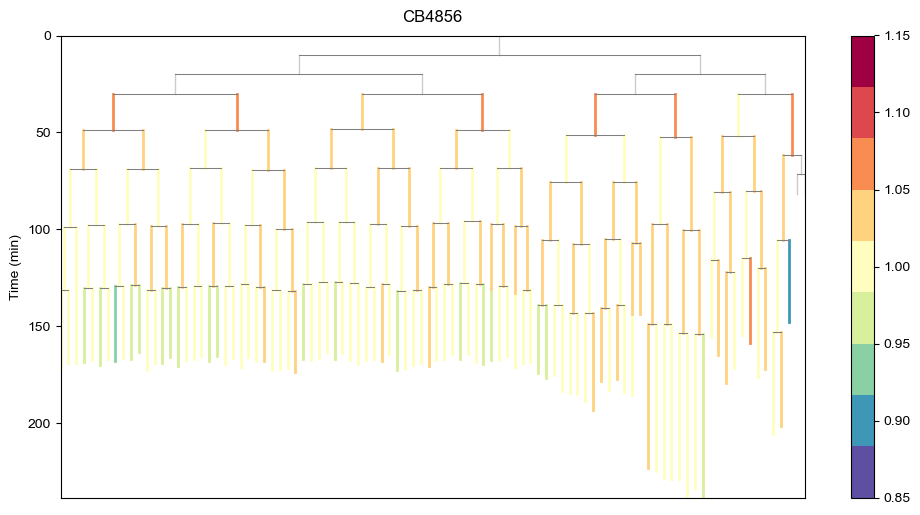

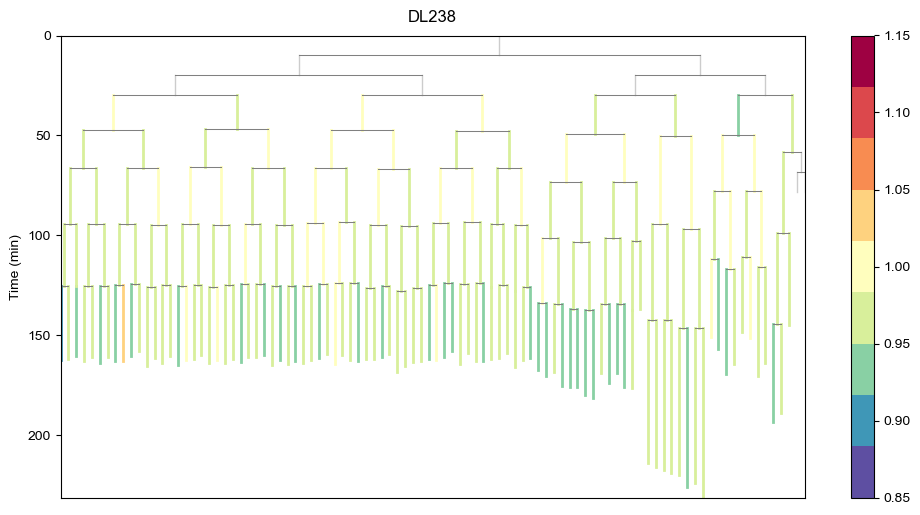

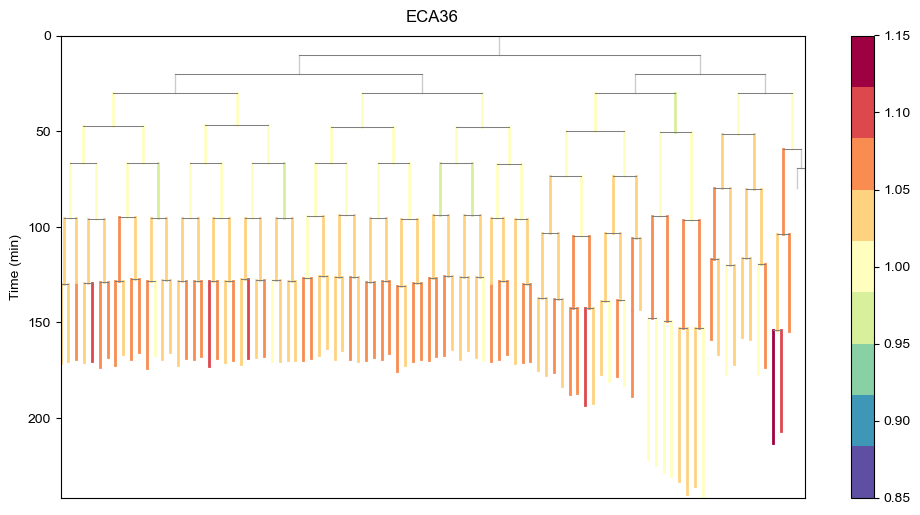

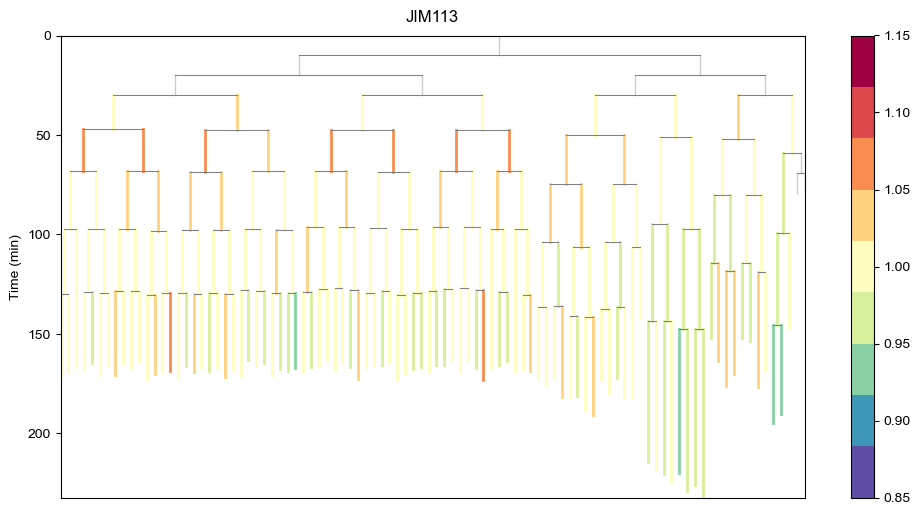

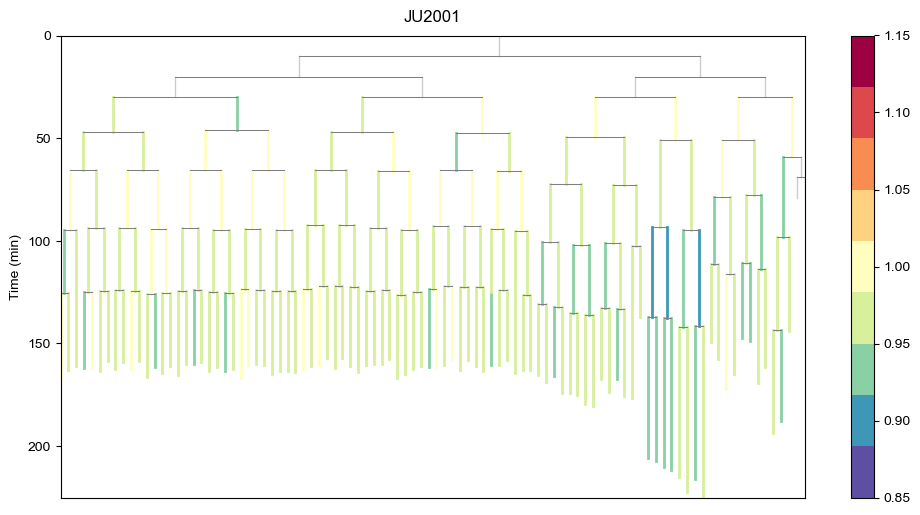

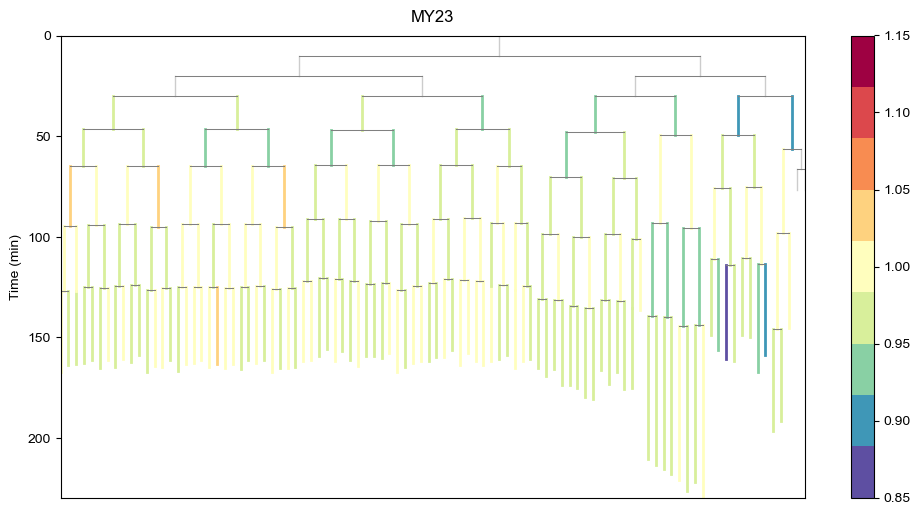

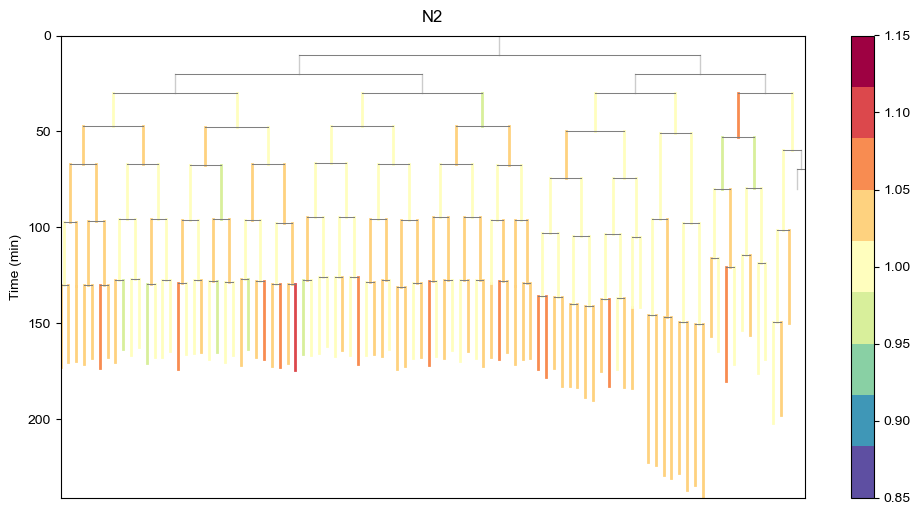

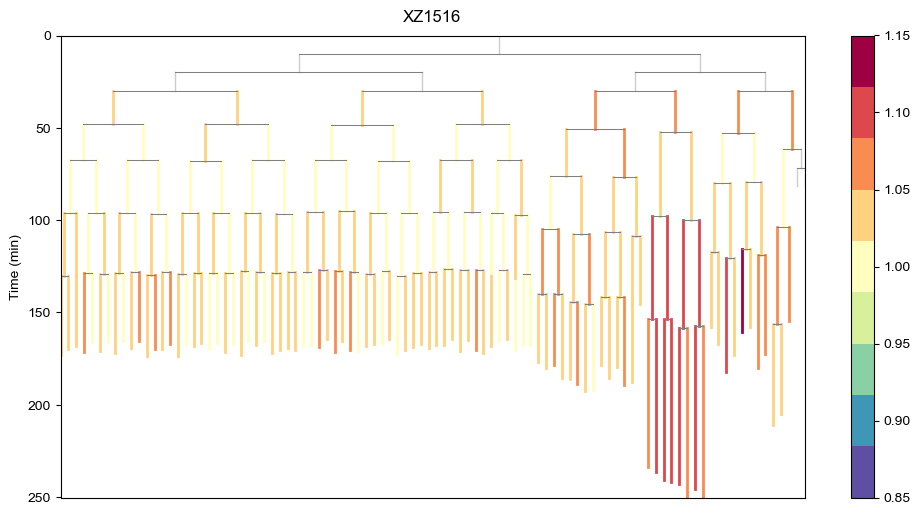

In [31]:
for strain in strain_avg.index:
    edge_lengths = strain_avg.loc[strain].values
    values = rate.loc[strain].values
    cell_names = strain_avg.columns.tolist()
    out = draw_lineage(
        cell_names=cell_names,
        edge_lengths=edge_lengths,
        values=values,ShowLabels=False,
        DefaultLength=10.0,
        CMap="Spectral_r", CLim = [0.85,1.15], Title = strain)
    out['ax'].figure.savefig(f"{strain}_rate.svg", format="svg")

## Figure 4: Scale vs. residual differences in developmental timing

In [32]:
its = 100000
ABala_lineage = []; ABalp_lineage = []; ABara_lineage = []; ABarp_lineage = []; 
ABpla_lineage = []; ABplp_lineage = []; ABpra_lineage = []; ABprp_lineage = []
MS_lineage = []; E_lineage = []; D_lineage = []; C_lineage = []
all_lineages = [ABala_lineage, ABalp_lineage, ABara_lineage, ABarp_lineage, ABpla_lineage, ABplp_lineage, ABpra_lineage, ABprp_lineage, MS_lineage, 
                    E_lineage, C_lineage, D_lineage]
lineage_sig_counts = {}
names = ['ABala', 'ABalp', 'ABara', 'ABarp', 'ABpla', 'ABplp', 'ABpra', 'ABprp', 'MS', 'E', 'C', 'D']
for embryo in fulldictlist:
    count = 0
    for n in all_lineages:
        n.append(node_comparison_trimmer(embryo, names[count]))
        count +=1
count = 0

In [33]:
def two_D_projection(u,v):
    #unit vector x basis
    x = u / np.linalg.norm(u)
    #make y orthogonal to x basis
    y = v - (np.dot(v, x))*x
    #unit vector y basis
    y = y / np.linalg.norm(y)
    #calculate projections
    u_x = np.dot(u,x)
    u_y = np.dot(u,y)
    v_x = np.dot(v,x)
    v_y = np.dot(v,y)
    return [u_x, u_y], [v_x, v_y]

keys = sorted(ABarp_lineage[0].keys())

#two arbitrary embryos for projection example
u = np.array([ABarp_lineage[23][k] for k in keys])
v = np.array([ABarp_lineage[75][k] for k in keys])

#project into 2D
u_proj, v_proj = two_D_projection(u, v)

u = np.array(u_proj)
v = np.array(v_proj)

In [34]:
bd = v - u
m = (u + v) / 2
m_scaled = m*1.2
#stil use original vectors for projections
unit_m = m/np.linalg.norm(m)
par_u = np.dot(u, unit_m) * unit_m
par_v = np.dot(v, unit_m) * unit_m
BD_par = par_v - par_u
BD_perp = bd - BD_par

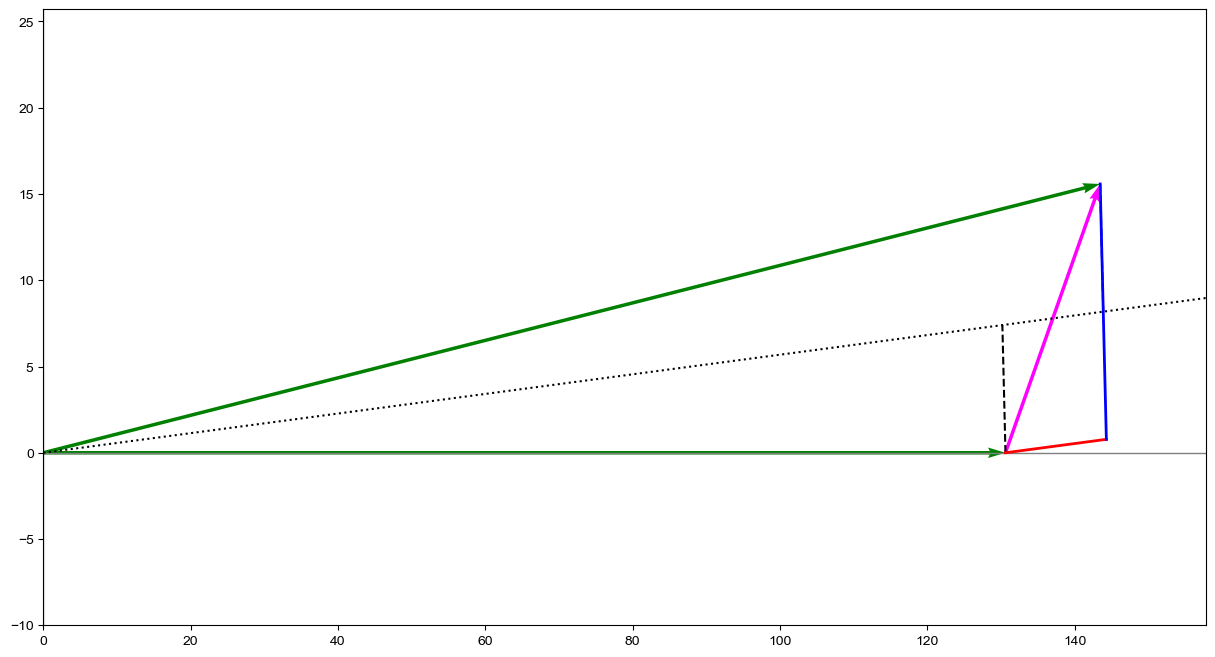

In [35]:
#plotting setup
plt.figure(figsize=(15, 8))
plt.axhline(0, color='gray', linewidth=1)
plt.axvline(0, color='gray', linewidth=1)


#VECTORS
#u
plt.quiver(0, 0, u_proj[0], u_proj[1],
           angles='xy', scale_units='xy', scale=1,
           color='green', label='u',
           width=0.003)
#v
plt.quiver(0, 0, v_proj[0], v_proj[1],
           angles='xy', scale_units='xy', scale=1,
           color='green', label='v',
           width=0.003)
#BD
plt.quiver(u[0], u[1], bd[0], bd[1],
           angles='xy', scale_units='xy', scale=1,
           color='magenta', width=0.003, label='BD')

#dashed mean vector
plt.plot([0, m_scaled[0]], [0, m_scaled[1]], linestyle=':', color='black')
#proj of u onto m
plt.plot([u[0], par_u[0]],[u[1], par_u[1]],linestyle='--', color='black', label='u → proj_m(u)')
#proj of v onto m
plt.plot([v[0], par_v[0]],[v[1], par_v[1]],linestyle='--', color='black', label='u → proj_m(u)')

end = u + BD_par

plt.plot([u[0], end[0]],[u[1], end[1]],color='red',linewidth=2,label='BD_par')
start = u + BD_par
plt.plot([start[0], v[0]],[start[1], v[1]],color='blue',linewidth=2,label='BD_perp')

#bounding on x and y axis
x_max = max(u_proj[0], v_proj[0])
pad_x = 0.1 * x_max if x_max != 0 else 1 
plt.xlim(0, x_max + pad_x)

y_max = max(abs(u_proj[1]), abs(v_proj[1]))
pad_y = 0.1 * y_max if y_max != 0 else 1

y_scale = 1.5
plt.ylim(-10, (y_max + pad_y) * y_scale)

#plt.gca().set_aspect('equal', adjustable='box')
plt.savefig('component_triangle.svg')
plt.show()

In [36]:
#Figure 1D source values: mean branch distance for every strain pair.
print(avg_df.round(2))


           N2  JIM113   MY23  JU2001  ECA36  CB4856  DL238  XZ1516
N2      38.72   44.23  51.13   56.43  53.78   47.82  54.99   53.04
JIM113  44.23   30.47  41.73   44.55  57.69   43.95  42.64   58.45
MY23    51.13   41.73  35.66   43.86  63.00   49.25  40.85   65.48
JU2001  56.43   44.55  43.86   38.84  68.33   53.06  42.31   71.47
ECA36   53.78   57.69  63.00   68.33  50.37   58.31  66.60   59.14
CB4856  47.82   43.95  49.25   53.06  58.31   41.73  49.17   58.98
DL238   54.99   42.64  40.85   42.31  66.60   49.17  34.88   68.17
XZ1516  53.04   58.45  65.48   71.47  59.14   58.98  68.17   50.60


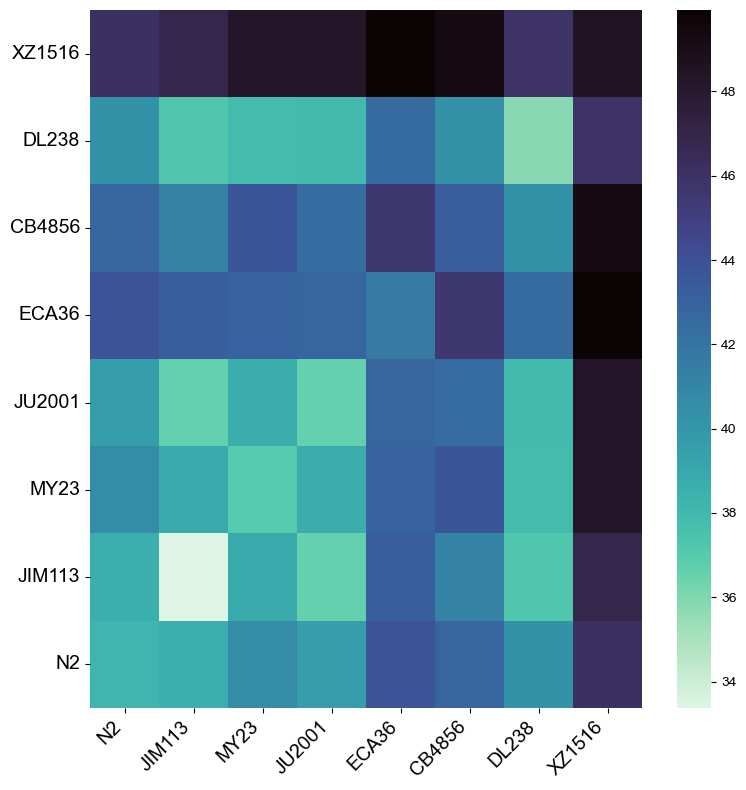

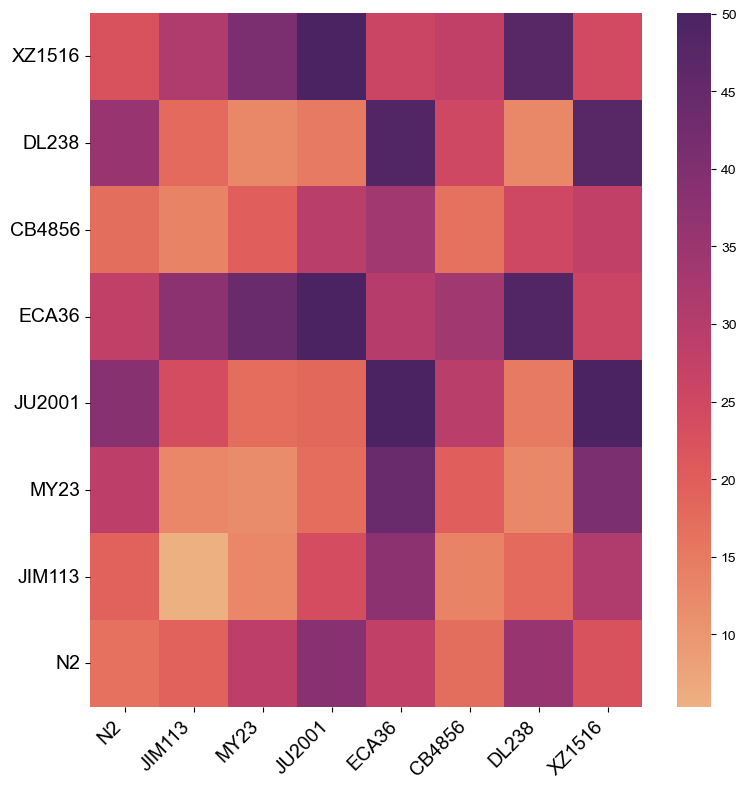

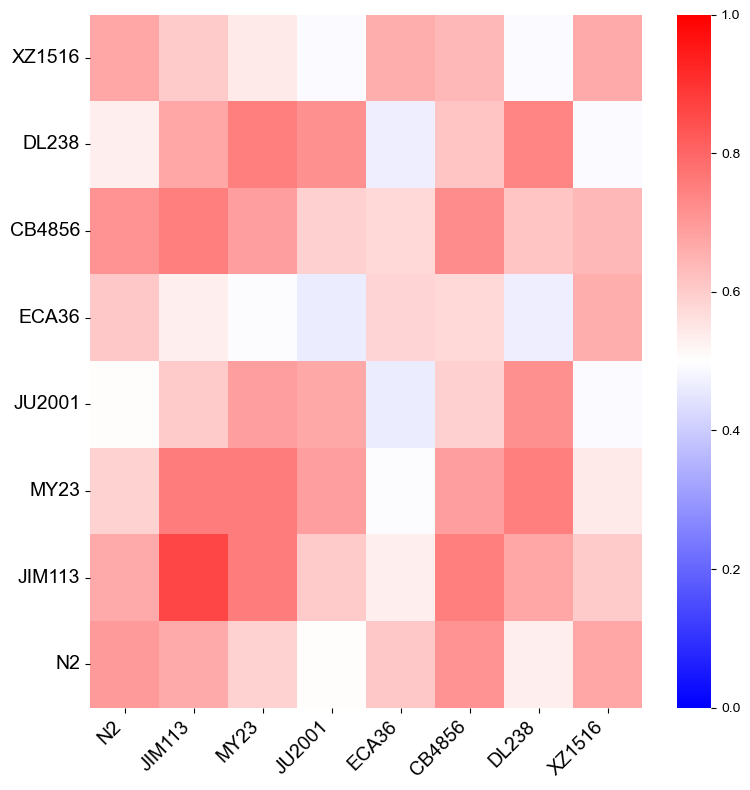

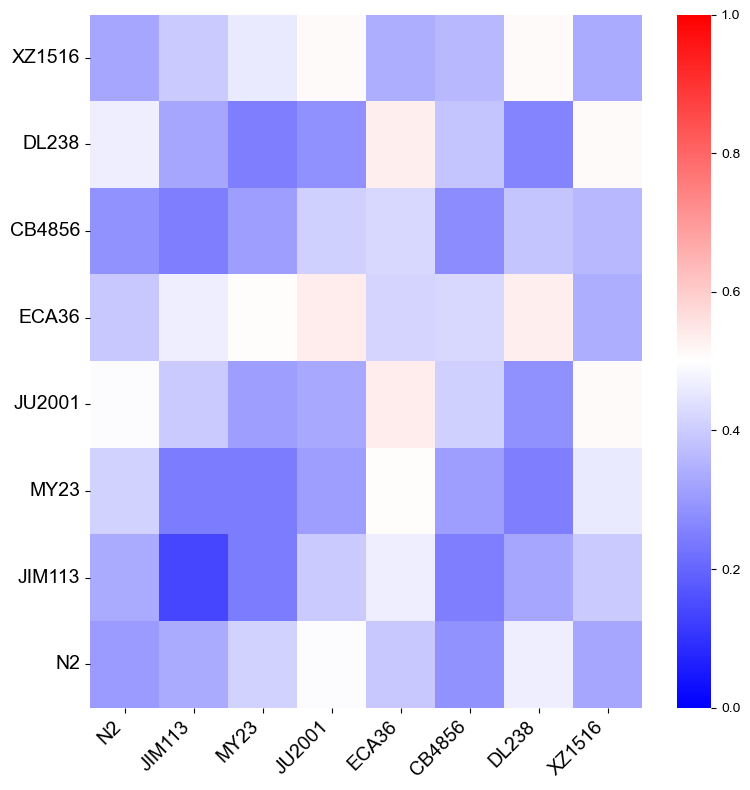

0.8611580171191896 6.255336021068341


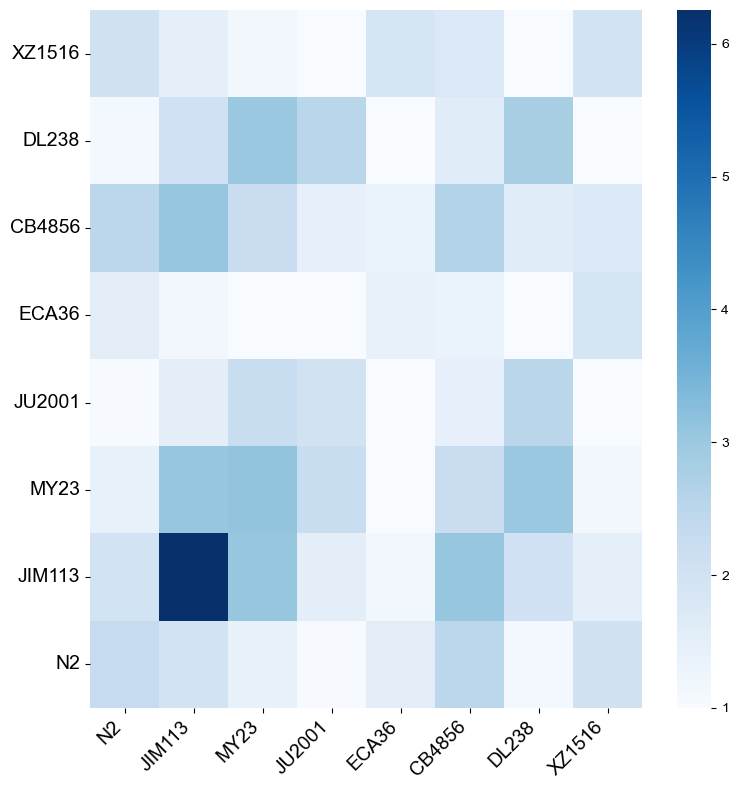

In [37]:
plot_heatmap(pd.DataFrame(perp[0]), "mako_r", min(pd.DataFrame(perp[0]).min()), max(pd.DataFrame(perp[0]).max()), name="perpendicular_heatmap.svg" )
plot_heatmap(pd.DataFrame(parallel[0]), "flare", min(pd.DataFrame(parallel[0]).min()), max(pd.DataFrame(parallel[0]).max()), name="parallel_heatmap.svg")
perp_ratio = (pd.DataFrame(perp[0]) / (pd.DataFrame(parallel[0]) + pd.DataFrame(perp[0])))
parallel_ratio = (pd.DataFrame(parallel[0]) / (pd.DataFrame(parallel[0]) + pd.DataFrame(perp[0])))
plot_heatmap(perp_ratio, "bwr", 0, 1, name="ratio_heatmap.svg")
plot_heatmap(parallel_ratio, "bwr", 0, 1, name="ratio_heatmap_parallel.svg")
total_ratio = pd.DataFrame(perp[0]) / (pd.DataFrame(parallel[0]))
print(min(total_ratio.min()), max(total_ratio.max()))
plot_heatmap(total_ratio, "Blues", 1, max(total_ratio.max()), name="total_ratio_heatmap.svg")
#do min max and then some fractional measure (divergent red - blu)
#use two colormaps, one for each heatmap


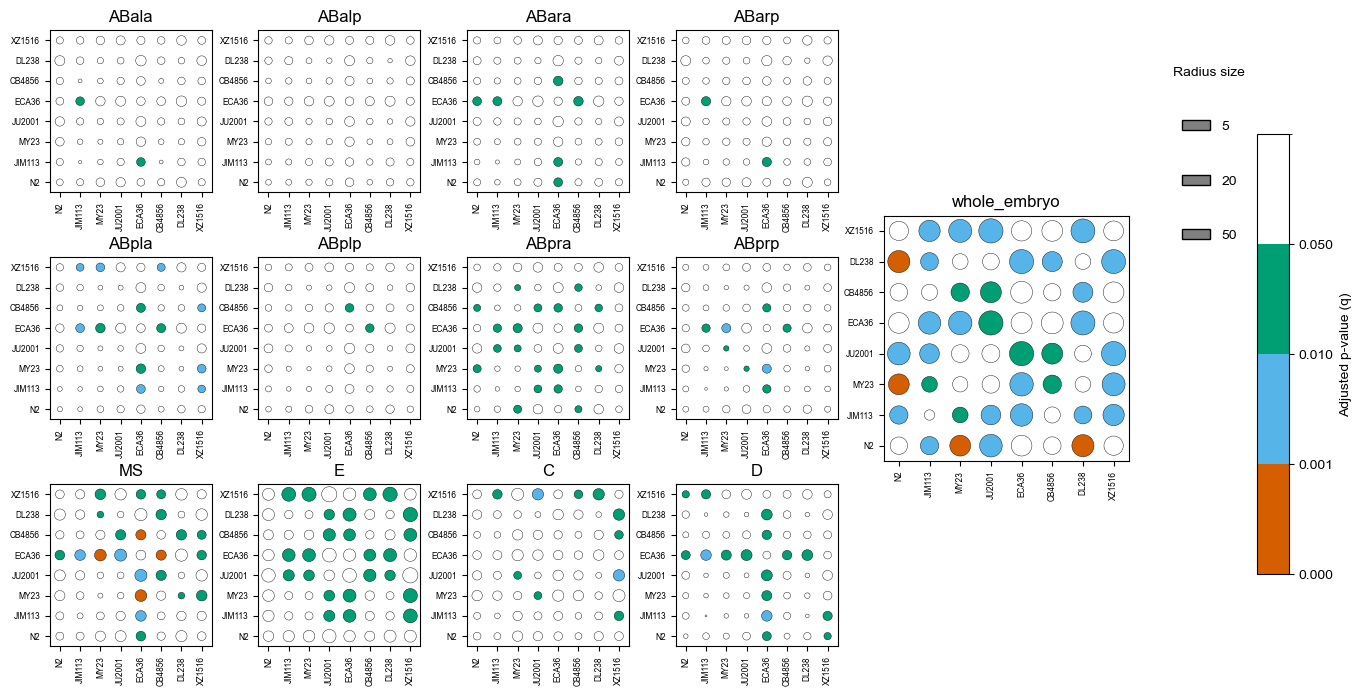

In [38]:
plot_lineage_pvalues(parallel, imports, "Parallel_BD.svg", mode="parallel")

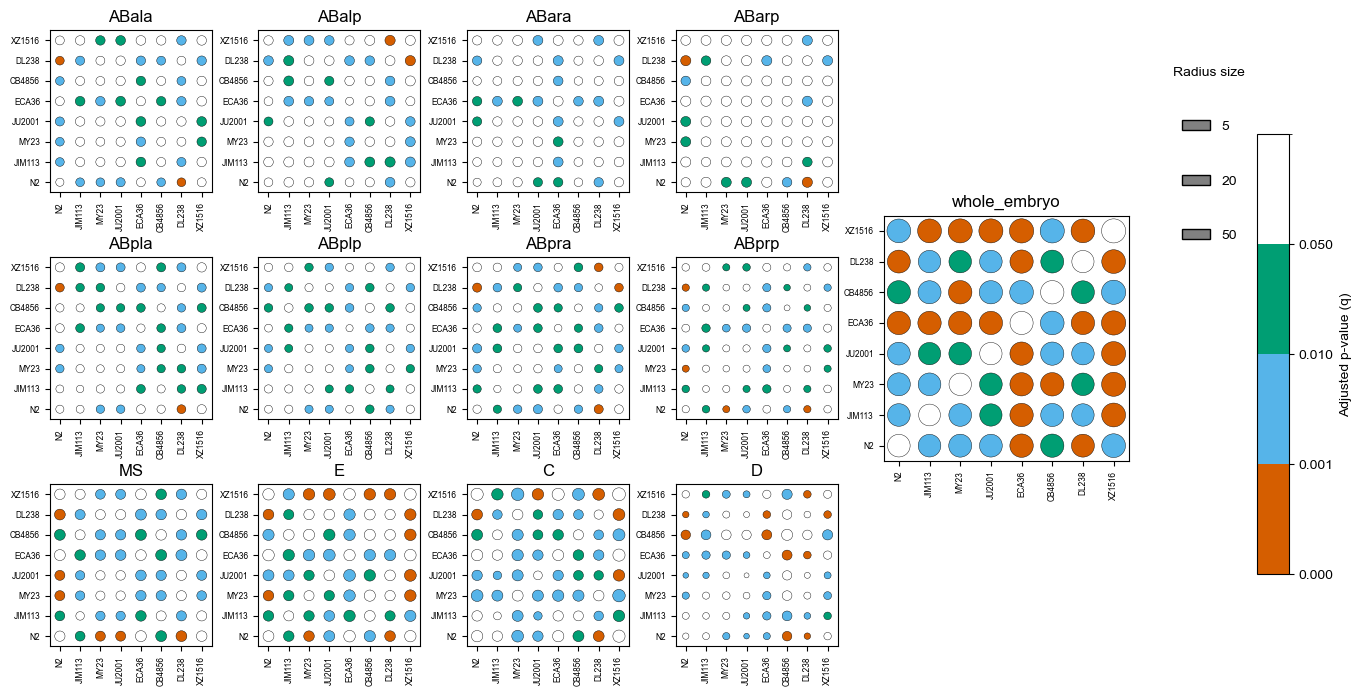

In [39]:
plot_lineage_pvalues(perp, imports, "Perpendicular_BD.svg", mode="perpendicular")

### Figure 3C / 4E-F: Tabulated counts of significant differences

In [40]:
def plot_pvalue_count_heatmap(imports, mode="normal", threshold=0.05,
                              title=None, cmap=plt.get_cmap('viridis_r', 7), save=None):
    table = make_pvalue_count_table(imports, mode=mode, threshold=threshold)
    heatmap_table = table.drop(columns=['total']) if 'total' in table.columns else table

    plt.figure(figsize=(10, 6))
    ax = sns.heatmap(heatmap_table, cmap=cmap, annot=False, fmt="d", cbar=True)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, ha='center')
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right')
    if all(isinstance(x, int) for x in table.index):
        ax.set_yticklabels([])
    ax.set_yticks(np.arange(len(table.index)) + 0.5)
    ax.set_xticks(np.arange(len(heatmap_table.columns)) + 0.5)

    if 'total' in table.columns:
        x_total = len(heatmap_table.columns) + 0.5
        for i, val in enumerate(table['total']):
            ax.text(x_total, i + 0.5, int(val), ha='center', va='center', color='black')
        ax.set_xlim(0, len(heatmap_table.columns) + 1)
        xticks = list(np.arange(len(heatmap_table.columns) + 1) + 0.5)
        xticklabels = list(heatmap_table.columns) + ['total']
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels, rotation=90, ha='center')

    plt.title(title or f"P-value count heatmap ({mode})")
    plt.xlabel("Strain")
    plt.ylabel("Lineage")
    plt.tight_layout()
    if save:
        plt.savefig(save)
    plt.show()
    return table

In [ ]:
threshold = 0.05
for mode in ["normal", "parallel", "perpendicular"]:
    print(f"Plotting p-value count heatmap for mode: {mode}")
    plot_pvalue_count_heatmap(
        imports,
        mode=mode,
        threshold=threshold,
        title=f" ",
        save=f"pvalue_count_{mode}.svg"
    )